# Лабораторная работа № 3
## Робастная линейная и логистическая регрессия

Данные: экспедиции на Эверест за 1921–2019 годы (Himalayan Database, подборка TidyTuesday). Датасет один на оба задания:

* задание 1, линейная регрессия: сколько персонала нанимает экспедиция;
* задание 2, логистическая регрессия: дошла ли она до вершины.



Обозначения и номера формул взяты из книги Maronna, Martin, Yohai «Robust Statistics: Theory and Methods», главы 5 и 7.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad
from scipy.optimize import check_grad, minimize
from sklearn.covariance import MinCovDet

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e4e3df", "axes.edgecolor": "#b5b4ae",
})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"

## 0. Данные

### 0.1. Загрузка и первый взгляд

In [2]:
df = pd.read_csv("everest-expeditions-tidytuesday.csv")
print(df.shape)
df.head()

(2149, 16)


,expedition_id,peak_id,peak_name,year,season,basecamp_date,highpoint_date,termination_date,termination_reason,highpoint_metres,members,member_deaths,hired_staff,hired_staff_deaths,oxygen_used,trekking_agency
0,EVER88401,EVER,Everest,1988,Winter,1988-11-10,1988-12-22,NaN,Accident (death or serious injury),8700.000,17,0,10,1,True,Mountain Travel
1,EVER88402,EVER,Everest,1988,Winter,1988-12-08,1989-01-10,1989-01-12,"Bad weather (storms, high winds)",7800.000,11,0,7,0,False,NaN
2,EVER89306,EVER,Everest,1989,Autumn,1989-08-21,1989-10-14,1989-10-15,"Bad weather (storms, high winds)",7800.000,2,0,0,0,True,NaN
3,EVER89310,EVER,Everest,1989,Autumn,1989-09-01,1989-09-25,1989-10-07,"Bad weather (storms, high winds)",7500.000,4,0,0,0,False,Trekking International
4,EVER89305,EVER,Everest,1989,Autumn,1989-08-17,1989-09-25,1989-10-01,"Bad conditions (deep snow, avalanching, fallin...",8100.000,6,0,0,0,False,Sherpa Society


In [3]:
pd.DataFrame({"тип": df.dtypes.astype(str), "пропуски": df.isna().sum(), "уникальных": df.nunique()})

,тип,пропуски,уникальных
expedition_id,object,0,2149
peak_id,object,0,1
peak_name,object,0,1
year,int64,0,74
season,object,0,4
basecamp_date,object,137,978
highpoint_date,object,74,746
termination_date,object,351,691
termination_reason,object,0,15
highpoint_metres,float64,40,116


In [4]:
df[["year", "members", "hired_staff", "highpoint_metres"]].describe()

,year,members,hired_staff,highpoint_metres
count,2149.000,2149.000,2149.000,2109.000
mean,2004.760,7.111,5.929,8399.756
std,11.912,7.499,8.842,830.694
min,1921.000,0.000,0.000,5100.000
25%,2000.000,2.000,1.000,8300.000
50%,2007.000,5.000,3.000,8850.000
75%,2013.000,10.000,8.000,8850.000
max,2019.000,99.000,99.000,8850.000


In [5]:
df["season"].value_counts()

season
Spring    1871
Autumn     224
Winter      30
Summer      24
Name: count, dtype: int64

Одна строка соответствует одной экспедиции, всего их 2149. В столбцах `members`, `hired_staff`, `year`, `season`, `oxygen_used` пропусков нет. `members` означает участников, `hired_staff` нанятых людей, обычно шерпов. Оба столбца сильно скошены вправо: третий квартиль 10 и 8 при максимуме 99.

Летних экспедиций 24, зимних 30. Для отдельных коэффициентов этого мало, поэтому сезон сводится к признаку «весна или нет».

У `members` минимум ноль, смотрим на эти строки.

In [6]:
df.loc[df["members"] == 0, ["expedition_id", "year", "members", "hired_staff", "termination_reason"]]

,expedition_id,year,members,hired_staff,termination_reason
464,EVER68101,1968,0,0,Attempt rumoured
467,EVER74102,1974,0,0,Did not attempt climb
473,EVER79102,1979,0,0,Did not attempt climb
478,EVER65102,1965,0,0,Attempt rumoured
479,EVER67101,1967,0,0,Did not attempt climb
480,EVER67301,1967,0,0,Did not attempt climb
1585,EVER13103,2013,0,16,Success (main peak)
1794,EVER16102,2016,0,9,Success (main peak)
1939,EVER17167,2017,0,9,Success (main peak)
1972,EVER18101,2018,0,8,Success (main peak)


Таких строк 13. Шесть экспедиций 1965–1979 годов не состоялись или известны по слухам. Остальные семь (2013–2019) состоят только из нанятых людей, скорее всего это бригады, которые провешивают перила. Обе задачи предполагают участников, поэтому строки удаляем.

Год переводим в десятилетия от 2000-го, чтобы коэффициент читался как изменение за 10 лет.

In [7]:
data = df[df["members"] > 0].copy()
data["decade"] = (data["year"] - 2000) / 10
data["spring"] = (data["season"] == "Spring").astype(int)
data["oxygen"] = data["oxygen_used"].astype(int)
print("экспедиций:", len(data))
data[["hired_staff", "members", "decade", "spring", "oxygen"]].describe().T

экспедиций: 2136


,count,mean,std,min,25%,50%,75%,max
hired_staff,2136.000,5.936,8.860,0.000,1.000,3.000,8.000,99.000
members,2136.000,7.154,7.501,1.000,2.000,5.000,10.000,99.000
decade,2136.000,0.482,1.178,-7.900,0.000,0.700,1.300,1.900
spring,2136.000,0.870,0.336,0.000,1.000,1.000,1.000,1.000
oxygen,2136.000,0.753,0.431,0.000,1.000,1.000,1.000,1.000


---
# Задание 1. Линейная регрессия

## 1.1. Выбор модели

Отклик `hired_staff`: сколько людей наняла экспедиция. Чем больше участников, тем больше нужно персонала, и прямая здесь разумное первое приближение. Коэффициент при `members` показывает, сколько людей нанимают на одного дополнительного участника.

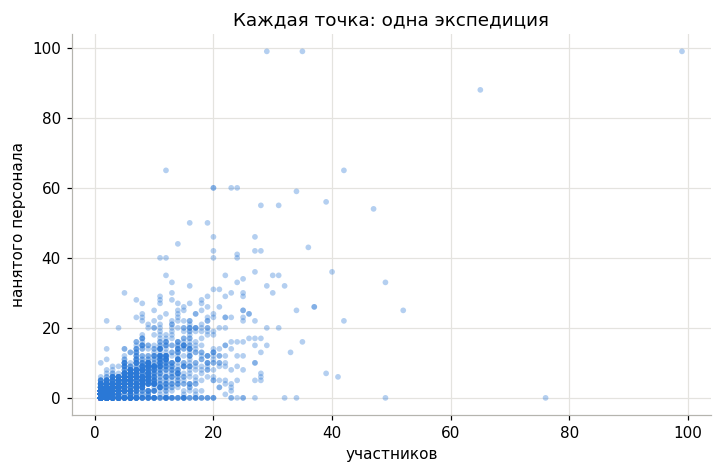

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(data["members"], data["hired_staff"], s=14, alpha=0.35, color=BLUE, edgecolor="none")
ax.set(xlabel="участников", ylabel="нанятого персонала", title="Каждая точка: одна экспедиция")
plt.show()

In [9]:
ratio = (data["hired_staff"] / data["members"]).groupby(data["year"] // 10 * 10)
pd.DataFrame({"экспедиций": ratio.size(), "медиана персонал/участник": ratio.median(),
              "доля без персонала": ratio.apply(lambda s: (s == 0).mean())})

,экспедиций,медиана персонал/участник,доля без персонала
year,,,
1920,3,2.333,0.000
1930,5,2.286,0.000
1940,1,2.000,0.000
1950,9,1.273,0.111
1960,12,1.227,0.417
1970,27,1.200,0.148
1980,141,0.364,0.319
1990,331,0.600,0.215
2000,745,0.800,0.183


Облако вытянуто вдоль прямой, но разброс растёт с размером экспедиции. Есть далёкие точки и полоса нулей, где никого не наняли. С 1980-х медианное отношение персонала к участникам выросло с 0.36 до 1.0. До 1980 года экспедиций всего 57, и на участника у них обычно приходилось больше одного человека персонала.

Модель:

$$\mathrm{hired\_staff}=\beta_0+\beta_1\,\mathrm{members}+\beta_2\,\mathrm{decade}+\beta_3\,\mathrm{spring}+\beta_4\,\mathrm{oxygen}+\varepsilon$$

`decade` равен (год − 2000)/10, `spring` и `oxygen` бинарные (весенний сезон, использование кислорода).

In [10]:
features = ["members", "decade", "spring", "oxygen"]
names = ["const"] + features
X = np.column_stack([np.ones(len(data)), data[features]]).astype(float)
y = data["hired_staff"].to_numpy(float)
n, p = X.shape
print("n =", n, " p =", p, " ранг X =", np.linalg.matrix_rank(X))

n = 2136  p = 5  ранг X = 5


## 1.2. Классические оценки: метод наименьших квадратов

Оценка минимизирует сумму квадратов остатков $r_i(\beta)=y_i-\beta'x_i$:

$$\hat\beta_{LS}=\arg\min_\beta\sum_{i=1}^n r_i(\beta)^2=(X'X)^{-1}X'y .$$

При нормальных ошибках с постоянной дисперсией это оценка максимального правдоподобия. Вклад наблюдения в уравнения равен $\psi(r)=r$ и ничем не ограничен, поэтому одно испорченное наблюдение может увести оценку сколь угодно далеко. Точка срыва равна 0.

In [11]:
XtX = X.T @ X
beta_ls = np.linalg.solve(XtX, X.T @ y)
pd.Series(beta_ls, index=names, name="МНК").to_frame().T

,const,members,decade,spring,oxygen
МНК,-2.872,0.761,-0.651,2.785,1.661


In [12]:
r_ls = y - X @ beta_ls
s_ls = np.sqrt(r_ls @ r_ls / (n - p))
R2 = 1 - r_ls @ r_ls / np.sum((y - y.mean()) ** 2)
print(f"s = {s_ls:.3f}   R² = {R2:.3f}")

s = 6.485   R² = 0.465


In [13]:
se_ls = s_ls * np.sqrt(np.diag(np.linalg.inv(XtX)))
t_ls = beta_ls / se_ls
pd.DataFrame({"оценка": beta_ls, "SE": se_ls, "t": t_ls,
              "p-value": 2 * stats.t.sf(np.abs(t_ls), n - p)}, index=names)

,оценка,SE,t,p-value
const,-2.872,0.466,-6.168,0.000
members,0.761,0.020,37.854,0.000
decade,-0.651,0.138,-4.703,0.000
spring,2.785,0.473,5.883,0.000
oxygen,1.661,0.338,4.915,0.000


По МНК один участник добавляет 0.76 человека персонала, весенний сезон 2.8, кислород 1.7. Коэффициент при `decade` отрицательный, минус 0.65 человека за десятилетие, хотя в таблице выше отношение с 1980-х растёт. По p-value значимы все коэффициенты.

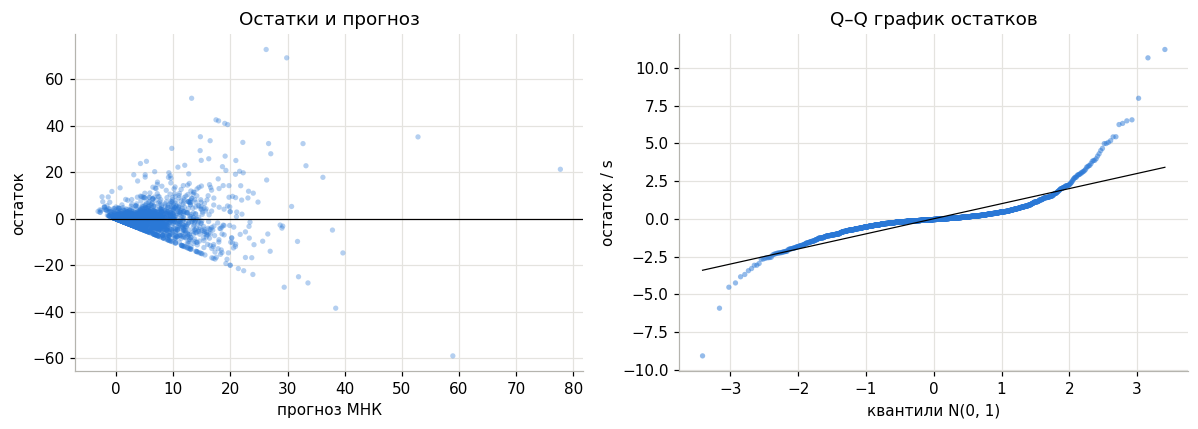

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X @ beta_ls, r_ls, s=12, alpha=0.35, color=BLUE, edgecolor="none")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="прогноз МНК", ylabel="остаток", title="Остатки и прогноз")
q, v = stats.probplot(r_ls / s_ls, fit=False)
axes[1].scatter(q, v, s=12, alpha=0.5, color=BLUE, edgecolor="none")
axes[1].plot(q, q, color="black", lw=0.8)
axes[1].set(xlabel="квантили N(0, 1)", ylabel="остаток / s", title="Q–Q график остатков")
plt.tight_layout()
plt.show()

In [15]:
print(f"асимметрия {stats.skew(r_ls):.2f}, эксцесс {stats.kurtosis(r_ls):.2f}")
rs = stats.spearmanr(np.abs(r_ls), X @ beta_ls)
print(f"корреляция Спирмена |остаток| и прогноза: {rs.statistic:.3f}")

асимметрия 2.17, эксцесс 25.42
корреляция Спирмена |остаток| и прогноза: 0.611


Наблюдения с самой большой разбалансировкой, leverage (диагональ матрицы $H=X(X'X)^{-1}X'$):

In [16]:
leverage = np.sum(X @ np.linalg.inv(XtX) * X, axis=1)
view = data[["expedition_id", "year", "members", "hired_staff"]].assign(
    leverage=leverage, stand_resid=r_ls / s_ls)
print("среднее p/n =", round(p / n, 4))
view.sort_values("leverage", ascending=False).head(8)

среднее p/n = 0.0023


,expedition_id,year,members,hired_staff,leverage,stand_resid
96,EVER88101,1988,99,99,0.077,3.280
1136,EVER08101,2008,76,0,0.046,-9.084
442,EVER21101,1921,9,21,0.034,1.401
443,EVER22101,1922,13,30,0.032,2.073
444,EVER24101,1924,11,40,0.031,3.870
386,EVER73101,1973,65,88,0.031,5.425
446,EVER34101,1934,1,2,0.027,-0.459
445,EVER33101,1933,16,50,0.025,5.172


И с самыми большими остатками:

In [17]:
view.loc[view["stand_resid"].abs().sort_values(ascending=False).index].head(8)

,expedition_id,year,members,hired_staff,leverage,stand_resid
460,EVER60102,1960,29,99,0.011,11.216
468,EVER75102,1975,35,99,0.009,10.662
1136,EVER08101,2008,76,0,0.046,-9.084
448,EVER36101,1936,12,65,0.024,7.984
407,EVER64101,1964,20,60,0.010,6.555
381,EVER75301,1975,23,60,0.006,6.487
463,EVER66101,1966,20,60,0.008,6.319
903,EVER05135,2005,24,60,0.003,6.242


Предпосылки МНК нарушены. Эксцесс остатков 25, хвосты на Q–Q графике намного тяжелее нормальных. Разброс растёт с прогнозом, корреляция Спирмена 0.61. Снизу облако остатков срезано наклонной прямой, потому что `hired_staff` не бывает отрицательным.

Среди точек с большим leverage 1988 год (99 участников и 99 нанятых), 2008 год (76 участников, ни одного нанятого) и экспедиции 1920–30-х. У многих из них большие и остатки. Ранние экспедиции брали много людей на участника, отсюда отрицательный тренд по годам.

## 1.3. MM-оценка

M-оценка регрессии минимизирует

$$L(\beta)=\sum_{i=1}^n\rho\!\left(\frac{r_i(\beta)}{\hat\sigma}\right).$$

С ограниченной $\rho$ грубые выбросы отбрасываются, но $L$ становится невыпуклой и ответ зависит от начальной точки. Ещё нужен масштаб $\hat\sigma$, который сами выбросы не испортили. MM-оценка (Yohai, 1987) строится так:

1. начальная оценка $\hat\beta_0$ с точкой срыва 0.5 (здесь S-оценка);
2. робастный масштаб $\hat\sigma$ остатков $r_i(\hat\beta_0)$;
3. M-оценка с более эффективной $\rho$, найденная итерациями от $\hat\beta_0$ при фиксированном $\hat\sigma$.

Точка срыва наследуется от первого шага, эффективность определяется третьим.

### 1.3.1. Функция потерь бисквадрат

$$\rho_c(u)=\begin{cases}1-\left(1-(u/c)^2\right)^3,&|u|\le c\\1,&|u|>c\end{cases}\qquad
W_c(u)=\begin{cases}\left(1-(u/c)^2\right)^2,&|u|\le c\\0,&|u|>c\end{cases}$$

Здесь $W_c$ вес наблюдения во взвешенном МНК, а $\psi_c(u)=u\,W_c(u)$ с точностью до множителя. Для S-шага берётся $c_0=1.547$ (масштаб состоятелен при нормальных ошибках, точка срыва 0.5), для M-шага $c_1=3.44$ (эффективность 85 % при нормальных ошибках). Условие $\rho_{c_0}\ge\rho_{c_1}$ выполнено, так как $c_1>c_0$.

In [18]:
C0, C1 = 1.547, 3.44

def rho_bi(u, c):
    return np.where(np.abs(u) <= c, 1 - (1 - (u / c) ** 2) ** 3, 1.0)

def w_bi(u, c):
    return np.where(np.abs(u) <= c, (1 - (u / c) ** 2) ** 2, 0.0)

u = np.array([0, 1, 2, 3, 4])
pd.DataFrame({"u": u, "rho, c0": rho_bi(u, C0), "W, c0": w_bi(u, C0),
              "rho, c1": rho_bi(u, C1), "W, c1": w_bi(u, C1)})

,u,"rho, c0","W, c0","rho, c1","W, c1"
0,0,0.000,1.000,0.000,1.000
1,1,0.803,0.339,0.233,0.838
2,2,1.000,0.000,0.710,0.438
3,3,1.000,0.000,0.986,0.057
4,4,1.000,0.000,1.000,0.000


### 1.3.2. M-оценка масштаба

Масштаб $\hat\sigma$ определяется уравнением

$$\frac1n\sum_{i=1}^n\rho_{c_0}\!\left(\frac{r_i}{\hat\sigma}\right)=\delta,\qquad \delta=0.5,$$

и находится простыми итерациями $\sigma_{k+1}^2=\sigma_k^2\cdot\frac{1}{\delta n}\sum_i\rho_{c_0}(r_i/\sigma_k)$, начиная с MADN.

In [19]:
def m_scale(r, delta=0.5):
    s = np.median(np.abs(r)) / 0.6745
    for _ in range(200):
        s_new = s * np.sqrt(np.mean(rho_bi(r / s, C0)) / delta)
        if abs(s_new / s - 1) < 1e-10:
            break
        s = s_new
    return s_new

print("проверка на N(0, 1):", round(m_scale(np.random.default_rng(0).standard_normal(100_000)), 4))

проверка на N(0, 1): 1.0003


In [20]:
pd.Series({"стандартное отклонение": r_ls.std(), "MADN": np.median(np.abs(r_ls)) / 0.6745,
           "M-масштаб": m_scale(r_ls)}, name="остатки МНК").to_frame()

,остатки МНК
стандартное отклонение,6.478
MADN,2.508
M-масштаб,2.687


MADN и M-масштаб дают 2.5 и 2.7, стандартное отклонение 6.5. Выбросы завысили обычную оценку масштаба примерно в 2.5 раза.

### 1.3.3. Начальная S-оценка

S-оценка минимизирует робастный масштаб остатков: $\hat\beta_S=\arg\min_\beta\hat\sigma(r(\beta))$. Минимум ищется методом подвыборок:

1. $N$ раз выбираем случайные $p$ наблюдений и проводим через них гиперплоскость точно;
2. каждого кандидата улучшаем одним шагом взвешенного МНК и считаем масштаб остатков;
3. десять лучших доводим до сходимости, побеждает кандидат с наименьшим масштабом.

Чтобы с вероятностью 0.99 хотя бы одна подвыборка оказалась без выбросов, нужно $N\ge|\ln 0.01|/(1-\varepsilon)^p$.

In [21]:
for eps in (0.10, 0.25, 0.50):
    print(f"доля выбросов {eps:.2f}: N >= {np.ceil(abs(np.log(0.01)) / (1 - eps) ** p):.0f}")

доля выбросов 0.10: N >= 8
доля выбросов 0.25: N >= 20
доля выбросов 0.50: N >= 148


С запасом берём $N=500$. Подвыборки с вырожденной матрицей (например, когда попали только весенние экспедиции) пропускаются.

In [22]:
def wls(X, y, w):
    sw = np.sqrt(w)
    return np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)[0]

def s_candidates(X, y, N=500, seed=0):
    rng = np.random.default_rng(seed)
    n, p = X.shape
    betas, skipped = [], 0
    while len(betas) < N:
        J = rng.choice(n, p, replace=False)
        if np.linalg.matrix_rank(X[J]) < p:
            skipped += 1
            continue
        r = y - X @ np.linalg.solve(X[J], y[J])
        betas.append(wls(X, y, w_bi(r / m_scale(r), C0)))
    scales = np.array([m_scale(y - X @ b) for b in betas])
    order = np.argsort(scales)
    return np.array(betas)[order], scales[order], skipped

cand, cand_scale, skipped = s_candidates(X, y)
print("пропущено вырожденных подвыборок:", skipped)
print("масштаб кандидатов: min {:.3f}, медиана {:.3f}, max {:.3f}".format(
    cand_scale[0], np.median(cand_scale), cand_scale[-1]))

пропущено вырожденных подвыборок: 947
масштаб кандидатов: min 2.349, медиана 3.325, max 6.500


In [23]:
pd.DataFrame(cand[:5], columns=names).assign(масштаб=cand_scale[:5])

,const,members,decade,spring,oxygen,масштаб
0,-2.000,0.667,0.181,1.018,1.748,2.349
1,-2.682,0.649,0.195,2.069,1.055,2.387
2,-0.466,0.662,0.884,-0.791,1.508,2.411
3,-2.393,0.973,0.540,0.668,1.049,2.416
4,-2.202,0.576,-0.108,1.423,1.921,2.424


Доводим десять лучших кандидатов. На каждой итерации масштаб пересчитывается, затем делается шаг взвешенного МНК с весами $W_{c_0}(r_i/\hat\sigma)$.

In [24]:
def s_refine(X, y, b):
    for _ in range(500):
        r = y - X @ b
        b_new = wls(X, y, w_bi(r / m_scale(r), C0))
        done = np.max(np.abs(b_new - b)) < 1e-9
        b = b_new
        if done:
            break
    return b, m_scale(y - X @ b)

refined = [s_refine(X, y, b) for b in cand[:10]]
pd.DataFrame([b for b, _ in refined], columns=names).assign(масштаб=[s for _, s in refined])

,const,members,decade,spring,oxygen,масштаб
0,-1.483,0.677,0.485,0.427,1.273,2.301
1,-1.483,0.677,0.485,0.427,1.273,2.301
2,-1.483,0.677,0.485,0.427,1.273,2.301
3,-1.483,0.677,0.485,0.427,1.273,2.301
4,-1.483,0.677,0.485,0.427,1.273,2.301
5,-1.483,0.677,0.485,0.427,1.273,2.301
6,-1.483,0.677,0.485,0.427,1.273,2.301
7,-1.483,0.677,0.485,0.427,1.273,2.301
8,-1.483,0.677,0.485,0.427,1.273,2.301
9,-1.483,0.677,0.485,0.427,1.273,2.301


In [25]:
beta_s, sigma = min(refined, key=lambda t: t[1])
pd.DataFrame([beta_ls, beta_s], columns=names, index=["МНК", "S-оценка"]).assign(масштаб=[s_ls, sigma])

,const,members,decade,spring,oxygen,масштаб
МНК,-2.872,0.761,-0.651,2.785,1.661,6.485
S-оценка,-1.483,0.677,0.485,0.427,1.273,2.301


Все десять кандидатов сошлись в одну точку, масштаб 2.301. Похоже, это глобальный минимум. У МНК масштаб ошибки был 6.485, и коэффициент при `decade` при переходе к S-оценке сменил знак.

### 1.3.4. M-шаг

При фиксированном $\hat\sigma$ решаем $\sum_i\psi_{c_1}(r_i/\hat\sigma)\,x_i=0$ итерациями взвешенного МНК от S-оценки. На каждой итерации $L(\beta)$ не растёт, поэтому условие $L(\hat\beta)\le L(\hat\beta_0)$ выполняется автоматически.

In [26]:
def m_step(X, y, b, sigma, c=C1):
    history = []
    for _ in range(1000):
        u = (y - X @ b) / sigma
        history.append([rho_bi(u, c).mean(), *b])
        b_new = wls(X, y, w_bi(u, c))
        done = np.max(np.abs(b_new - b)) < 1e-9
        b = b_new
        if done:
            break
    return b, history

beta_mm, history = m_step(X, y, beta_s, sigma)
history = pd.DataFrame(history, columns=["средняя потеря"] + names)
print("итераций:", len(history), " потеря не растёт:", bool((history["средняя потеря"].diff().dropna() <= 1e-12).all()))
history.iloc[[0, 1, 2, 5, 10, 20, len(history) - 1]].map("{:.5f}".format)

итераций: 60  потеря не растёт: True


,средняя потеря,const,members,decade,spring,oxygen
0,0.29360,-1.48305,0.67736,0.48539,0.42729,1.27258
1,0.29218,-1.21842,0.66446,0.64297,0.13903,1.31094
2,0.29189,-1.12481,0.65980,0.72190,-0.00329,1.31565
5,0.29176,-1.05648,0.65235,0.79004,-0.11717,1.31781
10,0.29174,-1.04138,0.64737,0.79735,-0.13168,1.32430
20,0.29174,-1.03738,0.64578,0.79712,-0.13362,1.32714
59,0.29174,-1.03713,0.64568,0.79709,-0.13374,1.32733


In [27]:
r_mm = y - X @ beta_mm
w_mm = w_bi(r_mm / sigma, C1)
print("вес 0:", (w_mm == 0).sum(), f"({(w_mm == 0).mean():.1%})   вес меньше 0.5: {(w_mm < 0.5).mean():.1%}   вес больше 0.9: {(w_mm > 0.9).mean():.1%}")

вес 0: 211 (9.9%)   вес меньше 0.5: 20.6%   вес больше 0.9: 55.2%


### 1.3.5. Стандартные ошибки

Из разложения оценочного уравнения получается «сэндвич»

$$\widehat{\mathrm{Cov}}(\hat\beta)=\frac{\hat\sigma^2}{n}A^{-1}BA^{-1},\qquad
A=\frac1n\sum_i\psi'(u_i)\,x_ix_i',\quad B=\frac1n\sum_i\psi(u_i)^2\,x_ix_i',\quad u_i=r_i/\hat\sigma .$$

Формула годится для всех трёх оценок: у МНК $\psi(u)=u$, у GM к $\psi$ добавляется вес $W(d(x_i))$. Масштаб считается известным. Одинаковой дисперсии ошибок формула не требует, а на графике остатков разброс явно растёт с прогнозом.

In [28]:
def psi_bi(u, c):
    return u * w_bi(u, c)

def dpsi_bi(u, c):
    return np.where(np.abs(u) <= c, (1 - (u / c) ** 2) * (1 - 5 * (u / c) ** 2), 0.0)

def sandwich_se(X, psi, dpsi, sigma):
    n = len(X)
    A_inv = np.linalg.inv((X.T * dpsi) @ X / n)
    B = (X.T * psi ** 2) @ X / n
    return sigma * np.sqrt(np.diag(A_inv @ B @ A_inv) / n)

se_ls_sw = sandwich_se(X, r_ls / s_ls, np.ones(n), s_ls)
se_mm = sandwich_se(X, psi_bi(r_mm / sigma, C1), dpsi_bi(r_mm / sigma, C1), sigma)
pd.concat({"МНК": pd.DataFrame({"оценка": beta_ls, "SE обычная": se_ls, "SE сэндвич": se_ls_sw, "z": beta_ls / se_ls_sw}, index=names),
           "MM": pd.DataFrame({"оценка": beta_mm, "SE сэндвич": se_mm, "z": beta_mm / se_mm}, index=names)}, axis=1)

МНК                                  MM                  
        оценка SE обычная SE сэндвич      z оценка SE сэндвич      z
const   -2.872      0.466      0.667 -4.306 -1.037      0.275 -3.772
members  0.761      0.020      0.062 12.375  0.646      0.036 17.886
decade  -0.651      0.138      0.341 -1.912  0.797      0.102  7.820
spring   2.785      0.473      0.761  3.661 -0.134      0.285 -0.468
oxygen   1.661      0.338      0.328  5.067  1.327      0.140  9.500

Выводы у MM и МНК разные.

* `decade`: −0.65 у МНК и +0.80 у MM. Со сэндвич-ошибкой тренд МНК незначим ($z=-1.9$).
* `spring`: 2.79 у МНК, у MM −0.13 при SE 0.29, то есть эффекта весны нет.
* `members`: 0.76 у МНК и 0.65 у MM.

Сэндвич-ошибки МНК в 1.4–3.1 раза больше обычных у всех коэффициентов, кроме `oxygen`. Нулевой вес в MM получили 211 экспедиций из 2136 (9.9 %).

## 1.4. Обобщённая M-оценка (GM)

Можно оставить монотонную $\psi$ и уменьшить вес наблюдений, далёких по $x$. Оценка Мэллоуза решает уравнение

$$\sum_{i=1}^n W(d(x_i))\,\psi\!\left(\frac{r_i(\beta)}{\hat\sigma}\right)x_i=0 ,$$

где $\psi$ Хьюбера: $\psi_k(u)=\max(-k,\min(k,u))$, $k=1.345$. Удалённость измеряем робастным расстоянием Махаланобиса $d(x)=\sqrt{(x-\hat\mu)'\hat\Sigma^{-1}(x-\hat\mu)}$. Центр $\hat\mu$ и ковариация $\hat\Sigma$ оцениваются по MCD: берутся те 75 % точек, у которых определитель ковариации наименьший. С весом $W(d)=\min(1,\,c/d)$, $c=\sqrt{\chi^2_{2;\,0.975}}$, произведение $W(d)\,d$ ограничено.

Расстояние считаем по `members` и `decade`. У бинарных признаков далёких значений нет.

In [29]:
Z = data[["members", "decade"]].to_numpy()
mcd = MinCovDet(support_fraction=0.75, random_state=0).fit(Z)
pd.DataFrame({"среднее": Z.mean(axis=0), "центр MCD": mcd.location_,
              "ст. откл.": Z.std(axis=0), "ст. откл. MCD": np.sqrt(np.diag(mcd.covariance_))},
             index=["members", "decade"])

,среднее,центр MCD,ст. откл.,ст. откл. MCD
members,7.154,4.625,7.500,3.610
decade,0.482,0.718,1.178,0.798


In [30]:
d = np.sqrt(mcd.mahalanobis(Z))
cut = np.sqrt(stats.chi2.ppf(0.975, 2))
W_x = np.minimum(1, cut / d)
print(f"порог {cut:.2f}, дальше порога {np.mean(d > cut):.1%} экспедиций, максимум d = {d.max():.1f}, наименьший вес {W_x.min():.3f}")
data[["expedition_id", "year", "members", "hired_staff"]].assign(d=d, W=W_x).sort_values("d", ascending=False).head(6)

порог 2.72, дальше порога 18.9% экспедиций, максимум d = 26.3, наименьший вес 0.103


,expedition_id,year,members,hired_staff,d,W
96,EVER88101,1988,99,99,26.308,0.103
1136,EVER08101,2008,76,0,20.208,0.134
386,EVER73101,1973,65,88,16.753,0.162
327,EVER80301,1980,52,25,13.148,0.207
1117,EVER07160,2007,49,0,12.546,0.217
385,EVER73301,1973,49,33,12.432,0.218


In [31]:
K = 1.345

def w_hub(u):
    return np.minimum(1, K / np.maximum(np.abs(u), 1e-12))

def gm_fit(X, y, W):
    b, history = wls(X, y, np.ones(len(y))), []
    for _ in range(500):
        r = y - X @ b
        s = m_scale(r)
        history.append([s, *b])
        b_new = wls(X, y, W * w_hub(r / s))
        done = np.max(np.abs(b_new - b)) < 1e-9
        b = b_new
        if done:
            break
    return b, s, history

beta_gm, sigma_gm, history = gm_fit(X, y, W_x)
history = pd.DataFrame(history, columns=["масштаб"] + names)
history.iloc[[0, 1, 2, 5, 10, len(history) - 1]]

,масштаб,const,members,decade,spring,oxygen
0,2.687,-2.872,0.761,-0.651,2.785,1.661
1,2.372,-1.760,0.742,0.426,0.687,1.540
2,2.359,-1.450,0.722,0.689,0.200,1.482
5,2.364,-1.302,0.702,0.788,0.012,1.480
10,2.365,-1.292,0.700,0.790,0.003,1.483
24,2.365,-1.292,0.700,0.790,0.003,1.483


Для сравнения та же оценка Хьюбера без весов по $x$ (все $W=1$):

In [32]:
beta_hub, sigma_hub, _ = gm_fit(X, y, np.ones(n))
u_gm = (y - X @ beta_gm) / sigma_gm
se_gm = sandwich_se(X, W_x * np.clip(u_gm, -K, K), W_x * (np.abs(u_gm) <= K), sigma_gm)
pd.DataFrame([beta_ls, beta_hub, beta_gm, beta_mm], columns=names,
             index=["МНК", "Хьюбер, W = 1", "GM (Мэллоуз)", "MM"]).assign(масштаб=[s_ls, sigma_hub, sigma_gm, sigma])

,const,members,decade,spring,oxygen,масштаб
МНК,-2.872,0.761,-0.651,2.785,1.661,6.485
"Хьюбер, W = 1",-1.567,0.703,0.547,0.529,1.457,2.345
GM (Мэллоуз),-1.292,0.700,0.790,0.003,1.483,2.365
MM,-1.037,0.646,0.797,-0.134,1.327,2.301


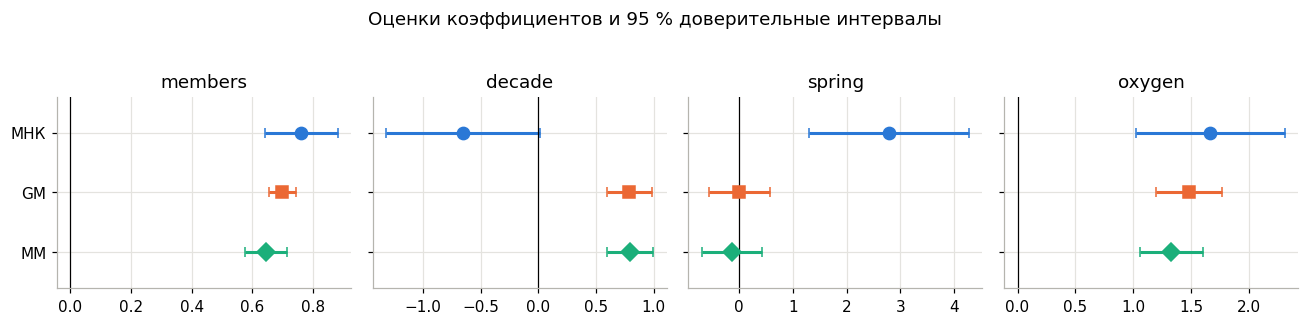

In [33]:
fits = {"МНК": (beta_ls, se_ls_sw, BLUE, "o"), "GM": (beta_gm, se_gm, ORANGE, "s"), "MM": (beta_mm, se_mm, AQUA, "D")}
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for j, ax in enumerate(axes, start=1):
    for pos, (label, (b, se, color, marker)) in enumerate(fits.items()):
        ax.errorbar(b[j], -pos, xerr=1.96 * se[j], color=color, marker=marker, ms=8, lw=2, capsize=3)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=names[j], yticks=[0, -1, -2], yticklabels=list(fits) if j == 1 else [], ylim=(-2.6, 0.6))
fig.suptitle("Оценки коэффициентов и 95 % доверительные интервалы", y=1.04)
plt.tight_layout()
plt.show()

GM почти совпала с MM: +0.79 за десятилетие, весна около нуля. Хьюбер без весов по $x$ остановился на полпути (0.55 и 0.53). Большие остатки он гасит, но далёкие по $x$ экспедиции продолжают тянуть оценку. Заметнее всего GM и MM расходятся в `members`, 0.70 и 0.65: у GM вес плохой точки мал, но нулём не становится.

GM считается проще, подвыборки не нужны. Зато её точка срыва меньше 0.5 и падает с ростом $p$, а у MM она 0.5.

## 1.5. Сравнение функций потерь

| | МНК | Хьюбер (GM) | бисквадрат (MM) |
|---|---|---|---|
| $\rho(u)$ | $u^2/2$ | $u^2/2$ при $\lvert u\rvert\le k$, иначе $k\lvert u\rvert-k^2/2$ | $1-(1-(u/c)^2)^3$ при $\lvert u\rvert\le c$, иначе $1$ |
| рост на бесконечности | квадратичный | линейный | ограничена |
| $\psi(u)$ | не ограничена | ограничена, монотонна | возвращается к нулю |
| вес выброса | $1$ | $k/\lvert u\rvert$ | $0$ |
| выпуклость | да | да | нет |

### 1.5.1. Форма функций

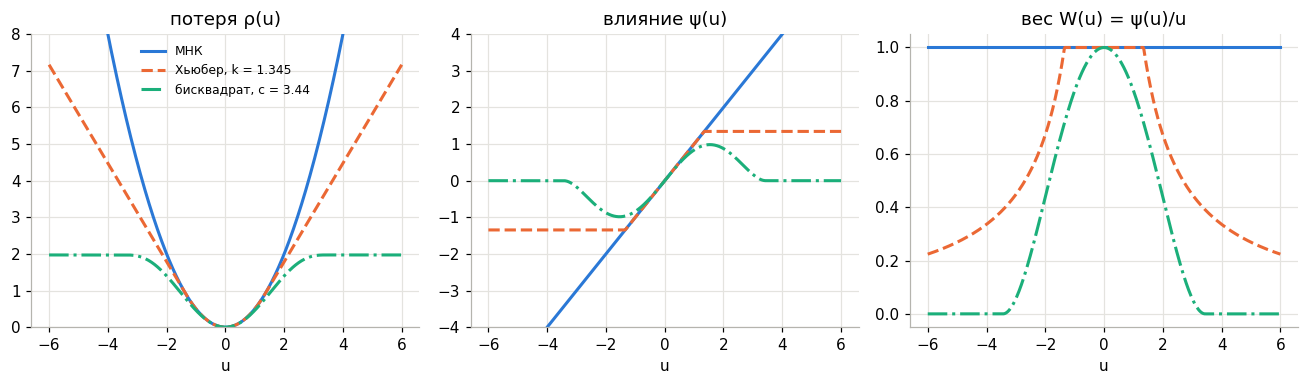

In [34]:
def rho_hub(u):
    return np.where(np.abs(u) <= K, u ** 2 / 2, K * np.abs(u) - K ** 2 / 2)

grid = np.linspace(-6, 6, 600)
norm_bi = C1 ** 2 / 6
curves = [("МНК", BLUE, "-", grid ** 2 / 2, grid, np.ones_like(grid)),
          ("Хьюбер, k = 1.345", ORANGE, "--", rho_hub(grid), np.clip(grid, -K, K), w_hub(grid)),
          ("бисквадрат, c = 3.44", AQUA, "-.", norm_bi * rho_bi(grid, C1), psi_bi(grid, C1), w_bi(grid, C1))]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for label, color, ls, rho_v, psi_v, w_v in curves:
    for ax, v in zip(axes, (rho_v, psi_v, w_v)):
        ax.plot(grid, v, color=color, ls=ls, lw=2, label=label)
axes[0].set(title="потеря ρ(u)", ylim=(0, 8), xlabel="u")
axes[1].set(title="влияние ψ(u)", ylim=(-4, 4), xlabel="u")
axes[2].set(title="вес W(u) = ψ(u)/u", xlabel="u")
axes[0].legend(loc="upper center", fontsize=8)
plt.tight_layout()
plt.show()

Бисквадрат умножен на $c^2/6$, чтобы около нуля все три кривые совпадали с $u^2/2$. Сколько экспедиций попадает в каждую область:

In [35]:
u_mm = r_mm / sigma
zones = pd.cut(np.abs(u_mm), [0, K, C1, np.inf], include_lowest=True,
               labels=["|u| ≤ 1.345: потери почти одинаковы", "1.345–3.44: Хьюбер и бисквадрат гасят", "> 3.44: бисквадрат постоянен"])
pd.DataFrame({"наблюдений": pd.Series(zones).value_counts(sort=False),
              "доля": pd.Series(zones).value_counts(sort=False, normalize=True)})

,наблюдений,доля
|u| ≤ 1.345: потери почти одинаковы,1531,0.717
1.345–3.44: Хьюбер и бисквадрат гасят,394,0.184
> 3.44: бисквадрат постоянен,211,0.099


### 1.5.2. Каждая оценка под каждой потерей

Средняя потеря при одном и том же масштабе $\hat\sigma$ S-оценки. У бисквадрата множитель $c^2/6$ оставлен.

In [36]:
def losses(b):
    u = (y - X @ b) / sigma
    return [np.mean(u ** 2 / 2), np.mean(rho_hub(u)), np.mean(norm_bi * rho_bi(u, C1))]

cross = pd.DataFrame([losses(b) for b in (beta_ls, beta_gm, beta_mm)], index=["МНК", "GM", "MM"],
                     columns=["квадратичная", "Хьюбера", "бисквадрат"])
cross

,квадратичная,Хьюбера,бисквадрат
МНК,3.964,1.428,0.643
GM,4.289,1.354,0.579
MM,4.439,1.365,0.575


In [37]:
((cross / cross.min() - 1) * 100).rename(columns=lambda c: c + ", проигрыш %").map("{:.1f}".format)

,"квадратичная, проигрыш %","Хьюбера, проигрыш %","бисквадрат, проигрыш %"
МНК,0.0,5.5,11.7
GM,8.2,0.0,0.6
MM,12.0,0.9,0.0


У МНК наименьшая квадратичная потеря, у MM наименьший бисквадрат, так и должно быть. GM минимизирует взвешенную потерю Хьюбера, а без весов минимум достигается при $W=1$, но из трёх строк она лучшая. МНК проигрывает по бисквадрату 11.7 %, MM по квадратичной 12.0 %. GM и MM по робастным потерям отличаются меньше чем на 1 %.

### 1.5.3. Откуда берётся потеря

Экспедиции упорядочены по величине остатка, самые далёкие идут первыми. По вертикали накопленная доля общей потери.

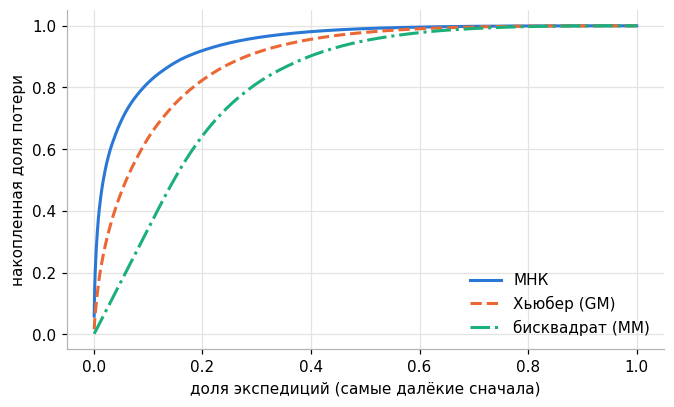

In [38]:
parts = {"МНК": (BLUE, "-", (r_ls / sigma) ** 2 / 2),
         "Хьюбер (GM)": (ORANGE, "--", rho_hub((y - X @ beta_gm) / sigma)),
         "бисквадрат (MM)": (AQUA, "-.", rho_bi(u_mm, C1))}
fig, ax = plt.subplots(figsize=(7, 4))
share = np.arange(1, n + 1) / n
for label, (color, ls, v) in parts.items():
    ax.plot(share, np.cumsum(np.sort(v)[::-1]) / v.sum(), color=color, ls=ls, lw=2, label=label)
ax.set(xlabel="доля экспедиций (самые далёкие сначала)", ylabel="накопленная доля потери")
ax.legend(loc="lower right")
plt.show()

In [39]:
pd.DataFrame({label: [np.sort(v)[::-1][: int(q * n)].sum() / v.sum() for q in (0.01, 0.05, 0.10)]
              for label, (_, _, v) in parts.items()}, index=["1 % самых далёких", "5 %", "10 %"])

,МНК,Хьюбер (GM),бисквадрат (MM)
1 % самых далёких,0.405,0.183,0.034
5 %,0.689,0.457,0.170
10 %,0.815,0.636,0.342


У МНК 1 % экспедиций (21 штука) даёт 40 % всей потери, 10 % дают 82 %. У бисквадрата это 3 % и 34 %. Прямой участок в начале его кривой соответствует наблюдениям с одинаковой максимальной потерей 1. Получается, что оценку МНК во многом определяют два десятка необычных экспедиций.

### 1.5.4. Профили потерь по одному коэффициенту

Коэффициент $\beta_j$ фиксируем на сетке, остальные подбираем заново и получаем профиль $\min_{\beta_{-j}}L(\beta)$. Его минимум стоит ровно в оценке. Каждая кривая поделена на свой минимум, чтобы их можно было сравнивать.

In [40]:
def profile(j, values):
    rest = [k for k in range(p) if k != j]
    out = []
    for val in values:
        yj = y - X[:, j] * val
        b_q = wls(X[:, rest], yj, np.ones(n))
        b_b, _ = m_step(X[:, rest], yj, beta_mm[rest], sigma)
        out.append([np.mean(((yj - X[:, rest] @ b_q) / sigma) ** 2) / 2,
                    np.mean(rho_bi((yj - X[:, rest] @ b_b) / sigma, C1))])
    return np.array(out)

prof_grids = {"decade": np.linspace(-2.5, 3, 56), "members": np.linspace(0.2, 1.2, 51), "spring": np.linspace(-3, 5, 41)}
prof = {name: profile(names.index(name), g) for name, g in prof_grids.items()}
pd.DataFrame({name: [g[prof[name][:, 0].argmin()], g[prof[name][:, 1].argmin()]] for name, g in prof_grids.items()},
             index=["минимум квадратичной потери", "минимум бисквадрата"])

,decade,members,spring
минимум квадратичной потери,-0.700,0.760,2.800
минимум бисквадрата,0.800,0.640,-0.200


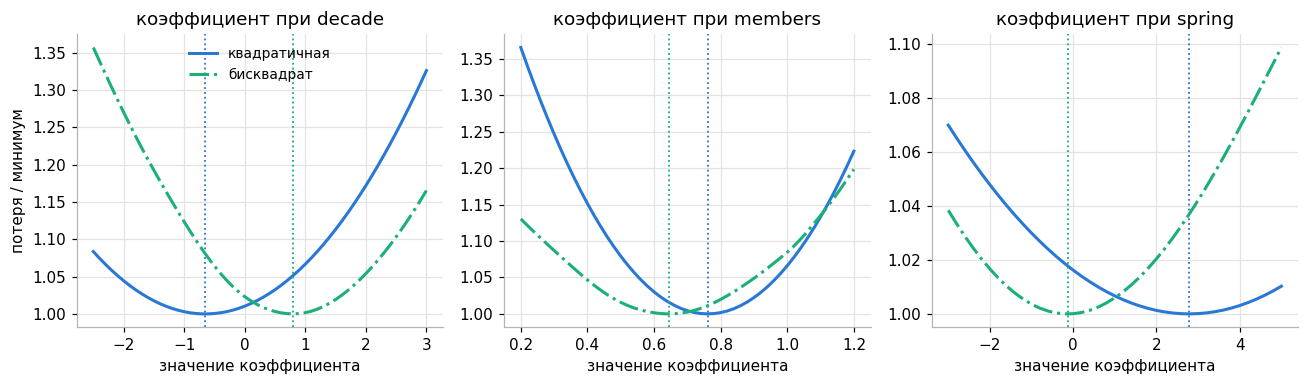

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, g) in zip(axes, prof_grids.items()):
    j = names.index(name)
    for col, (label, color, ls, b) in enumerate([("квадратичная", BLUE, "-", beta_ls), ("бисквадрат", AQUA, "-.", beta_mm)]):
        ax.plot(g, prof[name][:, col] / prof[name][:, col].min(), color=color, ls=ls, lw=2, label=label)
        ax.axvline(b[j], color=color, ls=":", lw=1.2)
    ax.set(title=f"коэффициент при {name}", xlabel="значение коэффициента", ylabel="потеря / минимум" if name == "decade" else "")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

### 1.5.5. Поверхность потерь в модели с двумя параметрами

Целиком поверхность рисуется только для двух параметров, поэтому здесь упрощённая модель $\mathrm{hired\_staff}=\beta_0+\beta_1\,\mathrm{members}$.

In [42]:
X2 = X[:, :2]
beta2_ls = wls(X2, y, np.ones(n))
b0 = s_candidates(X2, y)[0][0]
beta2_s, sigma2 = s_refine(X2, y, b0)
beta2_mm, _ = m_step(X2, y, beta2_s, sigma2)
pd.DataFrame([beta2_ls, beta2_mm], columns=["beta0", "beta1"], index=["МНК", "MM"])

,beta0,beta1
МНК,0.288,0.789
MM,0.471,0.635


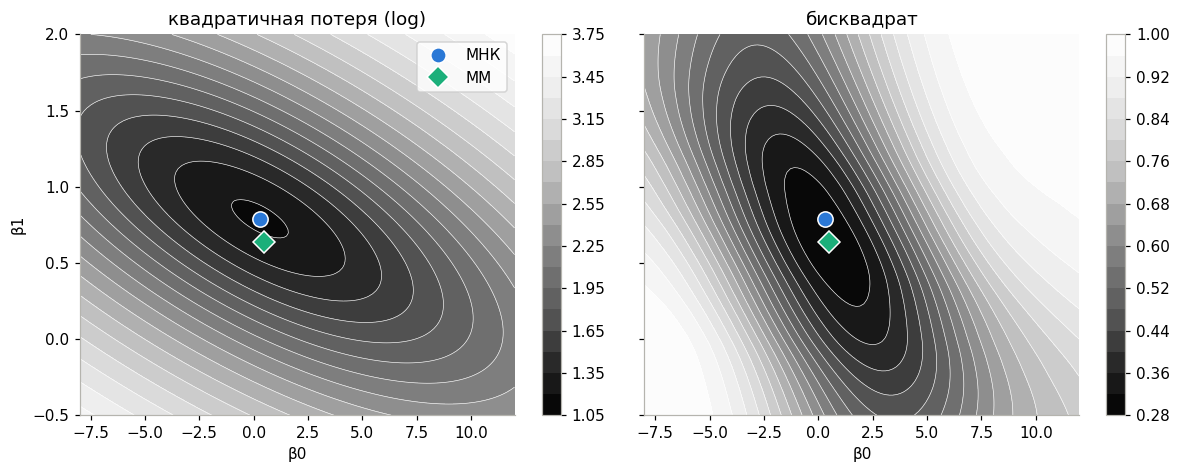

In [43]:
B0, B1 = np.meshgrid(np.linspace(-8, 12, 120), np.linspace(-0.5, 2.0, 120))
R = (y[:, None] - B0.ravel() - np.outer(X2[:, 1], B1.ravel())) / sigma2
surf = {"квадратичная потеря (log)": np.log(np.mean(R ** 2 / 2, axis=0)).reshape(B0.shape),
        "бисквадрат": np.mean(rho_bi(R, C1), axis=0).reshape(B0.shape)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (title, Z_) in zip(axes, surf.items()):
    cs = ax.contourf(B0, B1, Z_, 22, cmap="Greys_r")
    ax.contour(B0, B1, Z_, 22, colors="white", linewidths=0.4)
    ax.plot(*beta2_ls, "o", color=BLUE, ms=10, mec="white", label="МНК")
    ax.plot(*beta2_mm, "D", color=AQUA, ms=10, mec="white", label="MM")
    ax.set(title=title, xlabel="β0")
    ax.grid(False)
    fig.colorbar(cs, ax=ax)
axes[0].set_ylabel("β1")
axes[0].legend(loc="upper right", labelcolor="black", frameon=True)
plt.tight_layout()
plt.show()

### 1.5.6. Насколько визуализация разумна

В полной модели пять параметров, и целиком поверхность не нарисовать. Профиль показывает её вдоль одного коэффициента, а остальные подбирает, поэтому минимум профиля совпадает с оценкой. Если заморозить остальные коэффициенты, минимум сместится.

На профилях `decade` минимумы квадратичной потери и бисквадрата лежат по разные стороны от нуля. Квадратичный профиль для `spring` пологий: при нулевом коэффициенте потеря больше минимальной меньше чем на 2 %.

Контуры для двух параметров полные. У квадратичной потери это эллипсы. Бисквадрат вдали от минимума выходит на плато около 1, градиент там почти нулевой, и итерации, начатые оттуда, застрянут. Поэтому MM нужна хорошая начальная точка. Сама модель при этом упрощённая, её наклоны (0.79 у МНК и 0.64 у MM) полную не заменяют.

## 1.6. Природа выбросов (опционально)

По вертикали робастный остаток $u_i=r_i/\hat\sigma$, по горизонтали расстояние $d(x_i)$. Горизонтальные линии на $\pm 3.44$ (дальше вес в MM нулевой), вертикальная на пороге $d$.

In [44]:
out = np.abs(u_mm) > C1
far = d > cut
groups = [("обычные", ~out & ~far, GREY), ("хорошая разбалансировка", ~out & far, BLUE),
          ("вертикальные выбросы", out & ~far, ORANGE), ("плохая разбалансировка", out & far, AQUA)]
pd.DataFrame({"наблюдений": [m.sum() for _, m, _ in groups], "доля": [m.mean() for _, m, _ in groups]},
             index=[g[0] for g in groups])

,наблюдений,доля
обычные,1678,0.786
хорошая разбалансировка,247,0.116
вертикальные выбросы,55,0.026
плохая разбалансировка,156,0.073


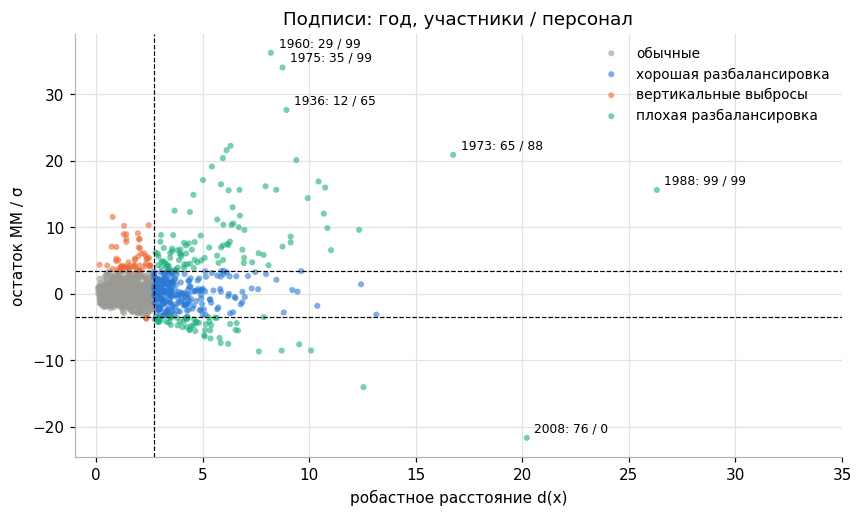

In [45]:
fig, ax = plt.subplots(figsize=(9, 5))
for label, mask, color in groups:
    ax.scatter(d[mask], u_mm[mask], s=16, alpha=0.6, color=color, edgecolor="none", label=label)
for h in (C1, -C1):
    ax.axhline(h, color="black", lw=0.8, ls="--")
ax.axvline(cut, color="black", lw=0.8, ls="--")
bad = np.where(out & far)[0]
top = set(bad[np.argsort(-np.abs(u_mm[bad]))[:3]]) | set(bad[np.argsort(-d[bad])[:3]])
for i in top:
    row = data.iloc[i]
    ax.annotate(f"{row['year']}: {row['members']} / {row['hired_staff']}", (d[i], u_mm[i]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="робастное расстояние d(x)", ylabel="остаток MM / σ", title="Подписи: год, участники / персонал")
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(-1, 35)
plt.show()

In [46]:
flag = data.assign(выброс=out, dec10=data["year"] // 10 * 10)
pd.DataFrame({"экспедиций": flag.groupby("dec10").size(),
              "выбросов вверх": flag[out & (u_mm > 0)].groupby("dec10").size(),
              "выбросов вниз": flag[out & (u_mm < 0)].groupby("dec10").size(),
              "доля выбросов": flag.groupby("dec10")["выброс"].mean()}).fillna(0)

,экспедиций,выбросов вверх,выбросов вниз,доля выбросов
dec10,,,,
1920,3,3.000,0.000,1.000
1930,5,4.000,0.000,0.800
1940,1,0.000,0.000,0.000
1950,9,5.000,0.000,0.556
1960,12,6.000,1.000,0.583
1970,27,16.000,1.000,0.630
1980,141,15.000,17.000,0.227
1990,331,18.000,21.000,0.118
2000,745,29.000,10.000,0.052


Размер экспедиций среди выбросов и среди остальных:

In [47]:
flag.groupby("выброс")[["members", "hired_staff"]].median().assign(
    доля_без_персонала=flag.groupby("выброс")["hired_staff"].apply(lambda s: (s == 0).mean()))

,members,hired_staff,доля_без_персонала
выброс,,,
False,4.000,3.000,0.185
True,16.000,20.000,0.175


Самые большие команды, которые не нанимали никого:

In [48]:
data.assign(u=u_mm)[data["hired_staff"] == 0].sort_values("u").head(6)[
    ["expedition_id", "year", "season", "members", "hired_staff", "trekking_agency", "u"]]

,expedition_id,year,season,members,hired_staff,trekking_agency,u
1136,EVER08101,2008,Spring,76,0,Chinese Mountaineering Association,-21.675
1117,EVER07160,2007,Spring,49,0,NaN,-14.062
51,EVER88305,1988,Autumn,32,0,NaN,-8.691
402,EVER70101,1970,Spring,34,0,NaN,-8.571
354,EVER97108,1997,Spring,27,0,Asian Trekking,-7.542
1428,EVER10116,2010,Spring,25,0,Mountain Consult,-7.431


Записи, где число людей равно ровно 99:

In [49]:
data.assign(u=u_mm)[(data["members"] == 99) | (data["hired_staff"] == 99)][
    ["expedition_id", "year", "members", "hired_staff", "u"]]

,expedition_id,year,members,hired_staff,u
96,EVER88101,1988,99,99,15.594
460,EVER60102,1960,29,99,36.210
468,EVER75102,1975,35,99,34.006


156 выбросов из 211 имеют большой leverage. Что это за экспедиции:

До 1980 года выбросами стали 36 экспедиций из 57, из них 34 вверх: на каждого участника приходилось много носильщиков. С 2000 года выбросов вверх 85, вниз 19. Медианный размер команды у выбросов 16 человек, у остальных 4. Среди выбросов вниз заметны команды без найма: 2008 год, 76 участников и 0 нанятых, 2007 год, 49 и 0. Вероятно, там рабочих записали в участники. В трёх записях (1960, 1975, 1988) число людей равно 99. Похоже на потолок поля из двух цифр, и реальные числа больше.

Явных ошибок, кроме потолка 99, не видно. Удалять эти экспедиции незачем. Но выбросы в основном крупные, а масштаб ошибки считается одинаковым для команды из 2 и из 40 человек. Это проверяется в разделе 1.8.

## 1.7. Выбор переменных (опционально)

Классический критерий FPE оценивает ошибку прогноза и штрафует за число признаков $q$:

$$FPE^*(C)=\frac1n\sum_i r_{iC}^2\left(1+\frac{2q}{n}\right).$$

Робастный вариант (5.53) заменяет квадрат ограниченной $\rho$ при общем масштабе $\hat\sigma$ полной модели:

$$RFPE^*(C)=\frac1n\sum_i\rho\!\left(\frac{r_{iC}}{\hat\sigma}\right)+\frac qn\cdot\frac{\hat A}{\hat B},\qquad
\hat A=\frac1n\sum_i\psi\!\left(\frac{r_{iC}}{\hat\sigma}\right)^2,\quad
\hat B=\frac1n\sum_i\psi'\!\left(\frac{r_{iC}}{\hat\sigma}\right).$$

Идём от полной модели и на каждом шаге убираем признак, без которого критерий наименьший. Подвыборки для каждого набора заново не считаем: стартовой точкой служит взвешенный МНК с весами полной модели. Добавлен признак `agency`, указано ли в базе трекинговое агентство.

In [50]:
data["agency"] = data["trekking_agency"].notna().astype(int)
cols = features + ["agency"]
XF = np.column_stack([X, data["agency"]])

def mm_fit(X, y, N=500):
    b, s = min((s_refine(X, y, c) for c in s_candidates(X, y, N)[0][:10]), key=lambda t: t[1])
    return m_step(X, y, b, s)[0], s

beta_full, sigma_full = mm_fit(XF, y)
print("масштаб полной модели:", round(sigma_full, 3))
pd.Series(beta_full, index=["const"] + cols).to_frame("MM, полная модель").T

масштаб полной модели: 2.294


,const,members,decade,spring,oxygen,agency
"MM, полная модель",-1.868,0.643,0.733,-0.211,1.284,1.029


In [51]:
def fpe(X, y, idx, sigma, w):
    r = y - X[:, idx] @ wls(X[:, idx], y, np.ones(len(y)))
    return np.mean(r ** 2) * (1 + 2 * len(idx) / len(y))

def rfpe(X, y, idx, sigma, w):
    b, _ = m_step(X[:, idx], y, wls(X[:, idx], y, w), sigma)
    u = (y - X[:, idx] @ b) / sigma
    A = np.mean((6 / C1 ** 2 * psi_bi(u, C1)) ** 2)
    B = np.mean(6 / C1 ** 2 * dpsi_bi(u, C1))
    return np.mean(rho_bi(u, C1)) + len(idx) / len(y) * A / B

def backward(crit, X, y, sigma, w):
    idx = list(range(X.shape[1]))
    rows = [["—", crit(X, y, idx, sigma, w), ", ".join(cols)]]
    while len(idx) > 2:
        score = {j: crit(X, y, [k for k in idx if k != j], sigma, w) for j in idx[1:]}
        j = min(score, key=score.get)
        idx.remove(j)
        rows.append([cols[j - 1], score[j], ", ".join(cols[k - 1] for k in idx[1:])])
    return pd.DataFrame(rows, columns=["убран", "критерий", "осталось"])

w_full = w_bi((y - XF @ beta_full) / sigma_full, C1)
path_ls = backward(fpe, XF, y, sigma_full, w_full)
path_ls

,убран,критерий,осталось
0,—,42.113,"members, decade, spring, oxygen, agency"
1,agency,42.158,"members, decade, spring, oxygen"
2,decade,42.556,"members, spring, oxygen"
3,spring,42.889,"members, oxygen"
4,oxygen,43.483,members


In [52]:
path_mm = backward(rfpe, XF, y, sigma_full, w_full)
path_mm.assign(критерий=path_mm["критерий"].map("{:.5f}".format))

,убран,критерий,осталось
0,—,0.29244,"members, decade, spring, oxygen, agency"
1,spring,0.29237,"members, decade, oxygen, agency"
2,agency,0.29299,"members, decade, oxygen"
3,oxygen,0.30021,"members, decade"
4,decade,0.31330,members


FPE выбирает полную модель. Если убирать признаки дальше, `spring` уходит третьим, после `agency` и `decade`. По RFPE `spring` уходит первым. Минимум 0.29237 у набора `members`, `decade`, `oxygen`, `agency`, у полной модели 0.29244, то есть весна почти ничего не даёт. Дальше ухудшение заметнее: 0.293 без `agency`, 0.300 без `oxygen`, 0.313 без `decade`. Классический критерий держится за весну и отдаёт десятилетие раньше неё, робастный делает наоборот.

## 1.8. Гетероскедастичная модель (опционально)

### 1.8.1. Как растёт разброс

In [53]:
fit_mm = X @ beta_mm
bins = pd.qcut(fit_mm, 8)
spread = pd.DataFrame({"прогноз": fit_mm, "r": r_mm}).groupby(bins, observed=True).agg(
    прогноз=("прогноз", "median"), наблюдений=("r", "size"),
    MADN=("r", lambda v: np.median(np.abs(v)) / 0.6745))
spread

,прогноз,наблюдений,MADN
"(-5.787, 0.838]",0.272,267,0.897
"(0.838, 1.679]",1.324,270,1.034
"(1.679, 2.325]",2.006,268,1.426
"(2.325, 3.548]",2.962,263,1.911
"(3.548, 4.987]",4.254,270,2.375
"(4.987, 6.685]",5.800,265,3.419
"(6.685, 9.737]",8.135,266,4.743
"(9.737, 63.123]",12.432,267,9.851


Разброс растёт почти пропорционально прогнозу. Модель с переменным масштабом:

$$y_i=\beta'x_i+h(\lambda,\beta'x_i)\,\varepsilon_i .$$

Алгоритм из раздела 5.13.1:

1. начальная MM-оценка $\hat\beta_0$ (уже есть);
2. остатки $r_i(\hat\beta_0)$;
3. $\hat\lambda$ из робастной регрессии $\ln|r_i|$ на функцию от $|\hat\beta_0'x_i|$;
4. MM-оценка по преобразованным данным $y_i^*=y_i/h_i$, $x_i^*=x_i/h_i$; шаги 2–4 повторяются до сходимости.

В книге в качестве примера взята $h=\exp(\lambda_1+\lambda_2|t|)$. Рядом проверим степенную $h=\exp(\lambda_1+\lambda_2\ln(1+|t|))$.

### 1.8.2. Выбор функции $h$

In [54]:
def fit_h(t, r, f):
    ok = np.abs(r) > 1e-8
    L = np.column_stack([np.ones(len(t)), f(t)])
    lam, _ = mm_fit(L[ok], np.log(np.abs(r[ok])))
    return lam, np.exp(L @ lam)

forms = {"экспонента": np.abs, "степень": lambda t: np.log1p(np.abs(t))}
first = {name: fit_h(fit_mm, r_mm, f) for name, f in forms.items()}
pd.DataFrame({name: [*lam, h.min(), h.max()] for name, (lam, h) in first.items()},
             index=["λ1", "λ2", "min h", "max h"])

,экспонента,степень
λ1,-0.356,-1.207
λ2,0.175,1.120
min h,0.703,0.304
max h,44090.149,31.602


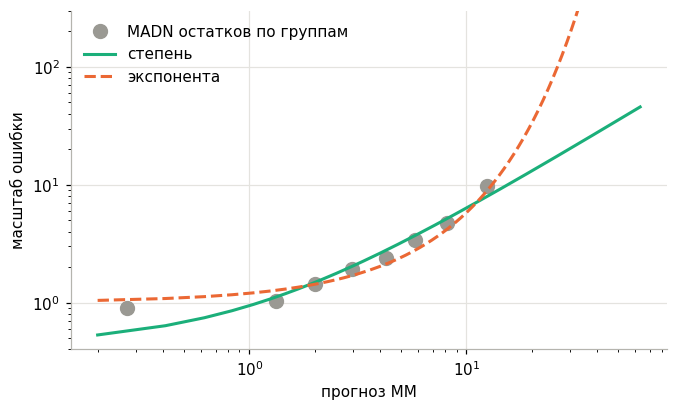

In [55]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(spread["прогноз"], spread["MADN"], "o", color=GREY, ms=9, label="MADN остатков по группам")
t = np.linspace(0.2, fit_mm.max(), 300)
scale0 = np.median(np.abs(r_mm) / first["степень"][1]) / 0.6745
scale1 = np.median(np.abs(r_mm) / first["экспонента"][1]) / 0.6745
ax.plot(t, scale0 * np.exp(first["степень"][0][0] + first["степень"][0][1] * np.log1p(t)), color=AQUA, lw=2, label="степень")
ax.plot(t, scale1 * np.exp(first["экспонента"][0][0] + first["экспонента"][0][1] * t), color=ORANGE, lw=2, ls="--", label="экспонента")
ax.set(xscale="log", yscale="log", ylim=(0.4, 300), xlabel="прогноз MM", ylabel="масштаб ошибки")
ax.legend()
plt.show()

Обе функции проходят через группы с прогнозом от 1 до 12, где лежит почти вся выборка. Дальше экспонента даёт нелепые значения: $h$ доходит до 44 090, у степени до 31.6. Берём степень. $\lambda_2=1.12$, масштаб ошибки растёт примерно пропорционально прогнозу. В самой левой группе (прогноз 0.27) степень занижает масштаб примерно в 1.6 раза.

### 1.8.3. Итерации

In [56]:
f = forms["степень"]
beta_h, rows = beta_mm.copy(), []
for k in range(1, 16):
    lam, h = fit_h(X @ beta_h, y - X @ beta_h, f)
    beta_new, sigma_h = mm_fit(X / h[:, None], y / h)
    shift = np.max(np.abs(beta_new - beta_h))
    beta_h = beta_new
    rows.append([k, *lam, *beta_h, sigma_h, shift])
    if shift < 1e-3:
        break
pd.DataFrame(rows, columns=["шаг", "λ1", "λ2"] + names + ["σ", "сдвиг β"]).set_index("шаг")

,λ1,λ2,const,members,decade,spring,oxygen,σ,сдвиг β
шаг,,,,,,,,,
1,-1.207,1.120,-1.313,0.607,0.469,0.361,1.337,1.424,0.495
2,-1.303,1.202,-1.417,0.610,0.387,0.492,1.369,1.470,0.131
3,-1.331,1.217,-1.460,0.612,0.358,0.539,1.385,1.483,0.047
4,-1.332,1.216,-1.482,0.613,0.346,0.564,1.392,1.487,0.025
5,-1.335,1.217,-1.494,0.613,0.341,0.577,1.395,1.489,0.013
6,-1.338,1.218,-1.501,0.613,0.339,0.584,1.397,1.491,0.007
7,-1.339,1.219,-1.505,0.613,0.338,0.588,1.398,1.492,0.004
8,-1.340,1.219,-1.507,0.613,0.337,0.590,1.399,1.492,0.002
9,-1.340,1.219,-1.509,0.613,0.337,0.591,1.399,1.493,0.001


In [57]:
Xh, yh = X / h[:, None], y / h
u_h = (yh - Xh @ beta_h) / sigma_h
se_h = sandwich_se(Xh, psi_bi(u_h, C1), dpsi_bi(u_h, C1), sigma_h)
pd.DataFrame({"MM": beta_mm, "SE MM": se_mm, "MM с h(x)": beta_h, "SE MM с h(x)": se_h,
              "SE: во сколько раз меньше": se_mm / se_h}, index=names)

,MM,SE MM,MM с h(x),SE MM с h(x),SE: во сколько раз меньше
const,-1.037,0.275,-1.510,0.145,1.893
members,0.646,0.036,0.613,0.020,1.788
decade,0.797,0.102,0.337,0.035,2.890
spring,-0.134,0.285,0.592,0.150,1.905
oxygen,1.327,0.140,1.400,0.061,2.306


### 1.8.4. Что изменилось

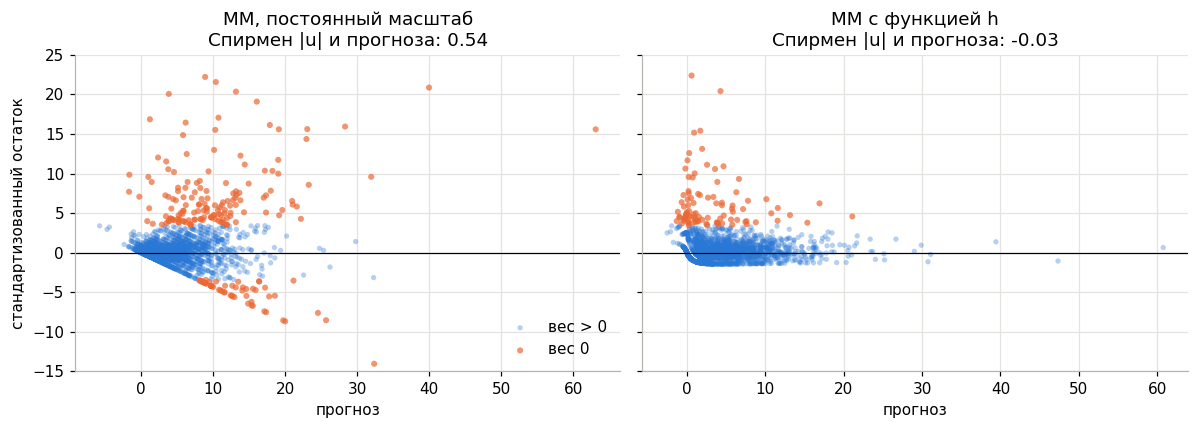

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, u_, fit_, title in [(axes[0], u_mm, fit_mm, "MM, постоянный масштаб"), (axes[1], u_h, X @ beta_h, "MM с функцией h")]:
    mask = np.abs(u_) > C1
    ax.scatter(fit_[~mask], u_[~mask], s=12, alpha=0.35, color=BLUE, edgecolor="none", label="вес > 0")
    ax.scatter(fit_[mask], u_[mask], s=16, alpha=0.7, color=ORANGE, edgecolor="none", label="вес 0")
    ax.axhline(0, color="black", lw=0.8)
    rho_s = stats.spearmanr(np.abs(u_), fit_).statistic
    ax.set(title=f"{title}\nСпирмен |u| и прогноза: {rho_s:.2f}", xlabel="прогноз", ylim=(-15, 25))
axes[0].set_ylabel("стандартизованный остаток")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [59]:
out_h = np.abs(u_h) > C1
print("выбросов при постоянном масштабе:", out.sum(), f"({out.mean():.1%})")
print("выбросов с функцией h:           ", out_h.sum(), f"({out_h.mean():.1%})")
print("общих:", (out & out_h).sum(), "  из них вверх:", (u_h[out_h] > 0).sum(), " вниз:", (u_h[out_h] < 0).sum())

выбросов при постоянном масштабе: 211 (9.9%)
выбросов с функцией h:            96 (4.5%)
общих: 46   из них вверх: 96  вниз: 0


In [60]:
kind = np.select([out & out_h, out, out_h], ["выброс в обеих моделях", "только при постоянном масштабе", "только с функцией h"], "не выброс")
data.groupby(kind)[["members", "hired_staff"]].median().assign(экспедиций=pd.Series(kind).value_counts())

,members,hired_staff,экспедиций
выброс в обеих моделях,9.500,26.000,46
не выброс,4.000,3.000,1875
только при постоянном масштабе,18.000,18.000,165
только с функцией h,2.000,4.000,50


In [61]:
data.assign(прогноз=X @ beta_h, u=u_h).sort_values("u", ascending=False).head(10)[
    ["expedition_id", "year", "season", "members", "hired_staff", "прогноз", "u"]]

,expedition_id,year,season,members,hired_staff,прогноз,u
447,EVER35201,1935,Summer,7,16,0.591,22.396
448,EVER36101,1936,Spring,12,65,4.281,20.431
572,EVER00141,2000,Spring,2,22,1.708,15.417
221,EVER94312,1994,Autumn,2,14,0.914,15.176
442,EVER21101,1921,Spring,9,21,1.937,13.123
1971,EVER17401,2017,Winter,2,7,0.289,12.588
1452,EVER11188,2011,Spring,1,5,0.066,11.678
455,EVER52301,1952,Autumn,7,23,2.563,11.110
444,EVER24101,1924,Spring,11,40,4.663,10.920
762,EVER03169,2003,Spring,1,5,-0.203,10.628


In [62]:
pd.crosstab(data["year"] // 10 * 10, out_h).rename(columns={False: "обычные", True: "выбросы"}).assign(
    доля=lambda t: t["выбросы"] / t.sum(axis=1))

col_0,обычные,выбросы,доля
year,,,
1920,0,3,1.000
1930,1,4,0.800
1940,1,0,0.000
1950,6,3,0.333
1960,7,5,0.417
1970,21,6,0.222
1980,133,8,0.057
1990,312,19,0.057
2000,724,21,0.028


Повторим отбор переменных на преобразованных данных:

In [63]:
XFh = XF / h[:, None]
beta_fh, sigma_fh = mm_fit(XFh, yh)
w_fh = w_bi((yh - XFh @ beta_fh) / sigma_fh, C1)
path_h = backward(rfpe, XFh, yh, sigma_fh, w_fh)
path_h.assign(критерий=path_h["критерий"].map("{:.5f}".format))

,убран,критерий,осталось
0,—,0.23857,"members, decade, spring, oxygen, agency"
1,agency,0.23885,"members, decade, spring, oxygen"
2,spring,0.24042,"members, decade, oxygen"
3,decade,0.24738,"members, oxygen"
4,oxygen,0.28369,members


Сходимость за 10 шагов. Корреляция Спирмена между $|u|$ и прогнозом упала с 0.54 до −0.03, стандартные ошибки уменьшились в 1.8–2.9 раза. Выбросов стало 96 вместо 211, общих 46. Перестали быть выбросами 165 крупных экспедиций (медиана 18 участников и 18 нанятых): при таком размере большой разброс нормален. Появились 50 маленьких (2 участника и 4 нанятых), которых общий масштаб не замечал. В обеих моделях выбросами остались экспедиции, где на 9–10 участников приходится 26 нанятых.

Все 96 выбросов вверх. В десятке самых больших остатков пять ранних экспедиций (1921, 1924, 1935, 1936, 1952) и пять современных групп из 1–2 участников с 5–22 нанятыми. Из восьми экспедиций 1920–30-х годов выбросами остались семь.

Коэффициент при `decade` теперь 0.34 вместо 0.80, при `spring` 0.59 ($z=3.9$) вместо нуля. При постоянном масштабе тренд определяли крупные экспедиции, теперь больше весят маленькие, а у них прирост в людях меньше. На преобразованных данных RFPE оставляет все пять признаков.

Снизу остатки упираются примерно в −1.5, потому что персонала не бывает меньше нуля. Распределение ошибок несимметрично, и свободный член смещён. Наклоны при ошибках, независимых от $x$, остаются состоятельными.

## 1.9. Итог задания 1

In [64]:
pd.DataFrame([beta_ls, beta_gm, beta_mm, beta_h], columns=names, index=["МНК", "GM", "MM", "MM с h(x)"])

,const,members,decade,spring,oxygen
МНК,-2.872,0.761,-0.651,2.785,1.661
GM,-1.292,0.700,0.790,0.003,1.483
MM,-1.037,0.646,0.797,-0.134,1.327
MM с h(x),-1.510,0.613,0.337,0.592,1.400


МНК даёт отрицательный и незначимый (по сэндвичу) тренд по годам, робастные оценки положительный и значимый. MM и GM устроены по-разному, но ответы близкие. Учёт гетероскедастичности сдвинул коэффициенты сильнее, чем выбор между MM и GM, и сократил число выбросов вдвое.

Итоговая модель (MM с $h$): на одного дополнительного участника 0.61 человека персонала, кислород добавляет 1.4, весна 0.6, десятилетие 0.34.

---
# Задание 2. Логистическая регрессия

## 2.1. Данные и модель

In [65]:
data["termination_reason"].value_counts()

termination_reason
Success (main peak)                                                             1314
Bad weather (storms, high winds)                                                 290
Other                                                                            154
Illness, AMS, exhaustion, or frostbite                                           123
Bad conditions (deep snow, avalanching, falling ice, or rock)                     78
Accident (death or serious injury)                                                51
Lack (or loss) of supplies or equipment                                           50
Route technically too difficult, lack of experience, strength, or motivation      38
Lack of time                                                                      11
Did not attempt climb                                                             11
Unknown                                                                            7
Success (claimed)                             

Успехом считаем `Success (main peak)`. Экспедиции, которые не начали восхождение, не дошли до базового лагеря, известны по слухам, закончились по неизвестной причине или заявили спорный успех, убираем: исход у них не определён. Таких строк 26. `Success (subpeak)` одна, она идёт в неудачи, до главной вершины группа не дошла.

In [66]:
unclear = ["Did not attempt climb", "Attempt rumoured", "Did not reach base camp", "Unknown", "Success (claimed)"]
climb = data[~data["termination_reason"].isin(unclear)].copy()
climb["success"] = (climb["termination_reason"] == "Success (main peak)").astype(int)
print("экспедиций:", len(climb), "  доля успеха:", round(climb["success"].mean(), 3))
pd.crosstab(climb["oxygen"], climb["success"], normalize="index")

экспедиций: 2110   доля успеха: 0.623


success,0,1
oxygen,,
0,0.929,0.071
1,0.203,0.797


С кислородом успешны 80 % экспедиций, без него 7 %. Кислород включают высоко на горе: кто повернул назад ниже, попадает в «без кислорода» как раз потому, что не дошёл. Признак почти содержит ответ, в модель его не берём. Остаются размер команды, персонал, год и сезон, они известны до выхода на гору.

In [67]:
bins = pd.cut(climb["hired_staff"], [-1, 0, 1, 2, 3, 5, 8, 12, 20, 40, 100],
              labels=["0", "1", "2", "3", "4–5", "6–8", "9–12", "13–20", "21–40", "41+"])
climb.groupby(bins, observed=True)["success"].agg(доля_успеха="mean", экспедиций="size").T

hired_staff,0,1,2,3,4–5,6–8,9–12,13–20,21–40,41+
доля_успеха,0.286,0.567,0.640,0.672,0.699,0.771,0.775,0.800,0.765,0.720
экспедиций,377.000,298.000,261.000,183.000,282.000,240.000,204.000,155.000,85.000,25.000


In [68]:
feats2 = ["members", "hired_staff", "decade", "spring"]
names2 = ["const"] + feats2
XS = np.column_stack([np.ones(len(climb)), climb[feats2]]).astype(float)
ys = climb["success"].to_numpy(float)
ns, ps = XS.shape
print("n =", ns, " p =", ps)

n = 2110  p = 5


Модель: $P(y_i=1\mid x_i)=F(\beta'x_i)$, $F(t)=e^t/(1+e^t)$, то есть

$$\ln\frac{P(\text{успех})}{P(\text{неудача})}=\beta_0+\beta_1\,\mathrm{members}+\beta_2\,\mathrm{hired\_staff}+\beta_3\,\mathrm{decade}+\beta_4\,\mathrm{spring}.$$

## 2.2. Классические оценки: максимальное правдоподобие

Обозначим $p_i=F(\beta'x_i)$. Логарифм правдоподобия и уравнения для ОМП:

$$\ell(\beta)=\sum_i\left[y_i\ln p_i+(1-y_i)\ln(1-p_i)\right],\qquad \sum_i(y_i-p_i)\,x_i=0 .$$

Решаем методом Ньютона: $\beta_{k+1}=\beta_k+\left(X'DX\right)^{-1}X'(y-p)$, $D=\mathrm{diag}(p_i(1-p_i))$.

Множитель $y_i-p_i$ ограничен, но $x_i$ нет, поэтому опасны точки с далёким $x$ и «неправильным» ответом. В линейной регрессии такие точки могут увести наклон в бесконечность, в логистической прижимают его к нулю (Croux, Flandre, Haesbroeck, 2002).

In [69]:
def prob(X, b):
    return 1 / (1 + np.exp(-X @ b))

b, rows = np.zeros(ps), []
for k in range(25):
    pr = prob(XS, b)
    rows.append([k, np.sum(ys * np.log(pr) + (1 - ys) * np.log(1 - pr)), *b])
    step = np.linalg.solve((XS.T * (pr * (1 - pr))) @ XS, XS.T @ (ys - pr))
    b = b + step
    if np.max(np.abs(step)) < 1e-10:
        break
beta_mle = b
pd.DataFrame(rows, columns=["итерация", "ln L"] + names2).set_index("итерация")

,ln L,const,members,hired_staff,decade,spring
итерация,,,,,,
0,-1462.541,0.000,0.000,0.000,0.000,0.000
1,-1240.834,-1.197,0.028,0.033,0.307,1.310
2,-1226.714,-1.554,0.041,0.058,0.412,1.470
3,-1226.123,-1.628,0.043,0.066,0.431,1.503
4,-1226.122,-1.631,0.043,0.066,0.431,1.505
5,-1226.122,-1.631,0.043,0.066,0.431,1.505


In [70]:
pr = prob(XS, beta_mle)
se_mle = np.sqrt(np.diag(np.linalg.inv((XS.T * (pr * (1 - pr))) @ XS)))
z = beta_mle / se_mle
pd.DataFrame({"ОМП": beta_mle, "SE": se_mle, "z": z, "p-value": 2 * stats.norm.sf(np.abs(z)),
              "отношение шансов": np.exp(beta_mle)}, index=names2)

,ОМП,SE,z,p-value,отношение шансов
const,-1.631,0.173,-9.424,0.000,0.196
members,0.043,0.011,4.073,0.000,1.044
hired_staff,0.066,0.011,6.259,0.000,1.068
decade,0.431,0.055,7.838,0.000,1.539
spring,1.505,0.171,8.778,0.000,4.503


Значимы все коэффициенты. Один нанятый человек увеличивает шансы на 6.8 %, весна в 4.5 раза, десятилетие в 1.5 раза. Эффект персонала выглядит слабым. По таблице выше доля успеха растёт с 0.29 без персонала до 0.77 при 6–8 людях, логит меняется на 2.1. При коэффициенте 0.066 для этого нужно около 32 человек.

## 2.3. Взвешенные M-оценки

### 2.3.1. Идея

ОМП минимизирует сумму квадратов девиансных остатков $\sum_i d_i^2$, где

$$d_i^2=-2\left[y_i\ln p_i+(1-y_i)\ln(1-p_i)\right].$$

Девианс не ограничен: если $y_i=0$, а $p_i\to1$, то $d_i^2\to\infty$. Bianco и Yohai (1996) заменили $d^2$ на $\rho(d^2)$ с медленно растущей $\rho$ и добавили поправку $q$, без которой оценка несостоятельна по Фишеру. Croux и Haesbroeck (2003) предложили конкретную $\psi=\rho'$ и веса по $x$. Взвешенная M-оценка (7.17) минимизирует

$$M(\beta)=\sum_{i=1}^n w_i\left\{\rho\!\left(d_i^2\right)+q(p_i)\right\},\qquad q(u)=v(u)+v(1-u),\quad v(u)=2\int_0^u\psi(-2\ln t)\,dt ,$$

$$\psi(t)=\exp\!\left(-\sqrt{\max(t,c)}\right),\quad c=0.5,\qquad w_i=W(d(x_i)).$$

Функция $\rho$ отвечает за выбросы в ответе, веса $w_i$ за далёкие $x$. При $w_i=1$ получается M-оценка без весов, при $\rho(t)=t$ и $q=0$ взвешенная ОМП (WMLE).

### 2.3.2. Функции $\rho$ и $v$ в явном виде

Интегрируя $\psi$, получаем

$$\rho(t)=\begin{cases}t\,e^{-\sqrt c},&t\le c\\ c\,e^{-\sqrt c}+2(1+\sqrt c)e^{-\sqrt c}-2(1+\sqrt t)e^{-\sqrt t},&t>c\end{cases}$$

Для $v$ замена $t=e^{-s/2}$, $s=m^2$ при $u\le e^{-c/2}$ даёт

$$v(u)=2\int_{m_0}^{\infty}m\,e^{-m-m^2/2}dm=2\sqrt e\left[e^{-(m_0+1)^2/2}-\sqrt{2\pi}\,\bigl(1-\Phi(m_0+1)\bigr)\right],\quad m_0=\sqrt{-2\ln u},$$

а при $u>e^{-c/2}$ функция линейна с наклоном $2e^{-\sqrt c}$.

In [71]:
CH = 0.5
E = np.exp(-np.sqrt(CH))

def psi_ch(t):
    return np.exp(-np.sqrt(np.maximum(t, CH)))

def rho_ch(t):
    s = np.sqrt(np.maximum(t, CH))
    return np.where(t <= CH, t * E, CH * E + 2 * (1 + np.sqrt(CH)) * E - 2 * (1 + s) * np.exp(-s))

def v_ch(u):
    u0 = np.exp(-CH / 2)
    m0 = np.sqrt(-2 * np.log(np.minimum(u, u0)))
    low = 2 * np.sqrt(np.e) * (np.exp(-(m0 + 1) ** 2 / 2) - np.sqrt(2 * np.pi) * stats.norm.sf(m0 + 1))
    return low + 2 * E * np.maximum(u - u0, 0)

Проверка формул численным интегрированием:

In [72]:
us, ts = [0.05, 0.3, 0.7, 0.9, 0.99], [0.2, 0.5, 1, 4, 12]
pd.DataFrame({"u": us, "v(u)": [float(v_ch(np.array(u))) for u in us],
              "v численно": [2 * quad(lambda t: float(psi_ch(-2 * np.log(t))), 0, u)[0] for u in us],
              "t": ts, "ρ(t)": [float(rho_ch(np.array(t))) for t in ts],
              "ρ численно": [quad(lambda s: float(psi_ch(s)), 0, t)[0] for t in ts]}).map("{:.5g}".format)

,u,v(u),v численно,t,ρ(t),ρ численно
0,0.05,0.0063127,0.0063127,0.2,0.098614,0.098614
1,0.3,0.08283,0.08283,0.5,0.24653,0.24653
2,0.7,0.3326,0.3326,1,0.45846,0.45846
3,0.9,0.52466,0.52466,4,1.118,1.118
4,0.99,0.61341,0.61341,12,1.6505,1.6505


### 2.3.3. Веса по $x$

Робастное расстояние считаем по трём непрерывным признакам через MCD, вес $W(d)=\min(1,c/d)$ с $c=\sqrt{\chi^2_{3;\,0.975}}$.

In [73]:
ZS = climb[["members", "hired_staff", "decade"]].to_numpy()
mcd2 = MinCovDet(support_fraction=0.75, random_state=0).fit(ZS)
ds = np.sqrt(mcd2.mahalanobis(ZS))
cut_s = np.sqrt(stats.chi2.ppf(0.975, 3))
w_s = np.minimum(1, cut_s / ds)
print(f"порог {cut_s:.2f}, дальше порога {np.mean(ds > cut_s):.1%}, сумма весов {w_s.sum():.0f} из {ns}")
climb[["expedition_id", "year", "members", "hired_staff", "success"]].assign(d=ds, w=w_s).sort_values("w").head(8)

порог 3.06, дальше порога 26.7%, сумма весов 1882 из 2110


,expedition_id,year,members,hired_staff,success,d,w
460,EVER60102,1960,29,99,1,43.746,0.070
468,EVER75102,1975,35,99,1,41.095,0.074
1136,EVER08101,2008,76,0,1,35.505,0.086
448,EVER36101,1936,12,65,0,33.743,0.091
96,EVER88101,1988,99,99,1,32.526,0.094
386,EVER73101,1973,65,88,1,29.536,0.104
407,EVER64101,1964,20,60,0,26.541,0.115
463,EVER66101,1966,20,60,0,26.410,0.116


### 2.3.4. Функция потерь и градиент

$$\frac{\partial M}{\partial\beta}=-2\sum_i w_i\left[\psi(d_i^2)(y_i-p_i)-p_i(1-p_i)\bigl(\psi(-2\ln p_i)-\psi(-2\ln(1-p_i))\bigr)\right]x_i .$$

Вычитаемое слагаемое равно $\mathrm E\left[\psi(d_i^2)(y_i-p_i)\mid x_i\right]$, поэтому в истинной точке среднее градиента равно нулю и оценка состоятельна по Фишеру.

In [74]:
def deviance(b, X, y):
    pr = np.clip(prob(X, b), 1e-12, 1 - 1e-12)
    return pr, -2 * (y * np.log(pr) + (1 - y) * np.log(1 - pr))

def wm_loss(b, X, y, w):
    pr, d2 = deviance(b, X, y)
    return np.mean(w * (rho_ch(d2) + v_ch(pr) + v_ch(1 - pr)))

def wm_score(b, X, y, w):
    pr, d2 = deviance(b, X, y)
    mean = pr * (1 - pr) * (psi_ch(-2 * np.log(pr)) - psi_ch(-2 * np.log(1 - pr)))
    return -2 * (w * (psi_ch(d2) * (y - pr) - mean))[:, None] * X

def wm_grad(b, X, y, w):
    return wm_score(b, X, y, w).mean(axis=0)

print("ошибка градиента:", check_grad(wm_loss, wm_grad, beta_mle, XS, ys, w_s))

ошибка градиента: 4.211144808225803e-08


### 2.3.5. Минимизация

Функция невыпуклая, поэтому запускаем BFGS из трёх точек: нуля, ОМП и взвешенной ОМП.

In [75]:
def wmle_loss(b, X, y, w):
    return np.mean(w * deviance(b, X, y)[1])

def wmle_score(b, X, y, w):
    pr, _ = deviance(b, X, y)
    return -2 * (w * (y - pr))[:, None] * X

def wmle_grad(b, X, y, w):
    return wmle_score(b, X, y, w).mean(axis=0)

beta_wmle = minimize(wmle_loss, beta_mle, args=(XS, ys, w_s), jac=wmle_grad, method="BFGS").x
starts = {"ноль": np.zeros(ps), "ОМП": beta_mle, "WMLE": beta_wmle}
runs = {k: minimize(wm_loss, b0, args=(XS, ys, w_s), jac=wm_grad, method="BFGS") for k, b0 in starts.items()}
pd.DataFrame({k: [r.nit, r.fun, np.max(np.abs(r.jac)), *r.x] for k, r in runs.items()},
             index=["итераций", "M(β)", "max |градиент|"] + names2).T.map("{:.5f}".format)

,итераций,M(β),max |градиент|,const,members,hired_staff,decade,spring
ноль,27.00000,0.79163,0.00001,-2.49065,0.01816,0.23254,0.31671,2.14841
ОМП,26.00000,0.79163,0.00000,-2.49074,0.01817,0.23252,0.31675,2.14842
WMLE,25.00000,0.79163,0.00000,-2.49082,0.01818,0.23252,0.31678,2.14846


In [76]:
beta_wm = min(runs.values(), key=lambda r: r.fun).x
beta_m = minimize(wm_loss, beta_mle, args=(XS, ys, np.ones(ns)), jac=wm_grad, method="BFGS").x
pd.DataFrame([beta_mle, beta_wmle, beta_m, beta_wm], columns=names2,
             index=["ОМП", "WMLE: веса, без ρ", "M: ρ, без весов", "WM: ρ и веса"])

,const,members,hired_staff,decade,spring
ОМП,-1.631,0.043,0.066,0.431,1.505
"WMLE: веса, без ρ",-2.024,0.032,0.139,0.329,1.833
"M: ρ, без весов",-2.000,0.028,0.139,0.414,1.746
WM: ρ и веса,-2.491,0.018,0.233,0.317,2.148


### 2.3.6. Стандартные ошибки

Снова сэндвич $\frac1nH^{-1}QH^{-1}$: якобиан среднего градиента $H$ считаем численно, $Q=\frac1n\sum_i s_is_i'$ по вкладам наблюдений $s_i$.

In [77]:
def se_by(score, b, w):
    eps = 1e-5
    H = np.column_stack([(score(b + eps * e, XS, ys, w).mean(0) - score(b - eps * e, XS, ys, w).mean(0)) / (2 * eps)
                         for e in np.eye(ps)])
    s = score(b, XS, ys, w)
    H_inv = np.linalg.inv(H)
    return np.sqrt(np.diag(H_inv @ (s.T @ s / ns) @ H_inv.T) / ns)

one = np.ones(ns)
se_wmle, se_m, se_wm = se_by(wmle_score, beta_wmle, w_s), se_by(wm_score, beta_m, one), se_by(wm_score, beta_wm, w_s)
pd.concat({label: pd.DataFrame({"оценка": b, "SE": se}, index=names2) for label, b, se in
           [("ОМП", beta_mle, se_mle), ("WMLE", beta_wmle, se_wmle), ("M", beta_m, se_m), ("WM", beta_wm, se_wm)]}, axis=1)

ОМП         WMLE            M           WM      
            оценка    SE оценка    SE оценка    SE оценка    SE
const       -1.631 0.173 -2.024 0.196 -2.000 0.240 -2.491 0.275
members      0.043 0.011  0.032 0.014  0.028 0.014  0.018 0.016
hired_staff  0.066 0.011  0.139 0.019  0.139 0.034  0.233 0.033
decade       0.431 0.055  0.329 0.065  0.414 0.073  0.317 0.078
spring       1.505 0.171  1.833 0.187  1.746 0.216  2.148 0.248

Насколько результат зависит от весов: вместо весов Хьюбера возьмём семейство Кэрролла–Педерсона $W(d)=(1-d^2/c^2)^3$ при $d\le c$, из формулы (7.11), с двумя порогами.

In [78]:
rows = {"веса Хьюбера": beta_wm}
for q in (0.99, 0.95):
    c = np.quantile(ds, q)
    w_cp = np.where(ds <= c, (1 - (ds / c) ** 2) ** 3, 0.0)
    rows[f"Кэрролл–Педерсон, c = {c:.1f}"] = minimize(wm_loss, beta_wm, args=(XS, ys, w_cp), jac=wm_grad, method="BFGS").x
pd.DataFrame(rows, index=names2).T

,const,members,hired_staff,decade,spring
веса Хьюбера,-2.491,0.018,0.233,0.317,2.148
"Кэрролл–Педерсон, c = 18.5",-2.401,0.015,0.223,0.313,2.089
"Кэрролл–Педерсон, c = 8.4",-2.911,0.018,0.305,0.277,2.494


Коэффициент при персонале 0.066 у ОМП, 0.139 только с весами или только с $\rho$, 0.233 у WM. Каждый механизм увеличивает его вдвое, вместе в 3.5 раза. Это соответствует эффекту из 2.2: далёкие точки с неудачей (1936 год, 65 нанятых; 1964 и 1966, по 60) прижимают наклон к нулю. `members` у WM незначим (0.018 при SE 0.016), `spring` вырос с 1.5 до 2.1. За робастность платим точностью: SE при персонале 0.033 вместо 0.011.

Мягкие веса Кэрролла–Педерсона ($c=18.5$) дают почти то же, 0.223. Жёсткие ($c=8.4$) дают 0.305: чем слабее вклад крупных экспедиций, тем круче наклон. Похоже, дело в форме зависимости, а несколько плохих точек играют меньшую роль.

Доля успеха по группам и средняя вероятность от каждой модели:

In [79]:
calib = pd.DataFrame({"наблюдений": climb.groupby(bins, observed=True).size(),
                      "доля успеха": climb.groupby(bins, observed=True)["success"].mean(),
                      "ОМП": pd.Series(prob(XS, beta_mle), climb.index).groupby(bins, observed=True).mean(),
                      "WM": pd.Series(prob(XS, beta_wm), climb.index).groupby(bins, observed=True).mean()})
calib

,наблюдений,доля успеха,ОМП,WM
hired_staff,,,,
0,377,0.286,0.504,0.410
1,298,0.567,0.579,0.531
2,261,0.640,0.572,0.556
3,183,0.672,0.597,0.608
4–5,282,0.699,0.607,0.649
6–8,240,0.771,0.671,0.761
9–12,204,0.775,0.709,0.841
13–20,155,0.800,0.775,0.934
21–40,85,0.765,0.848,0.989


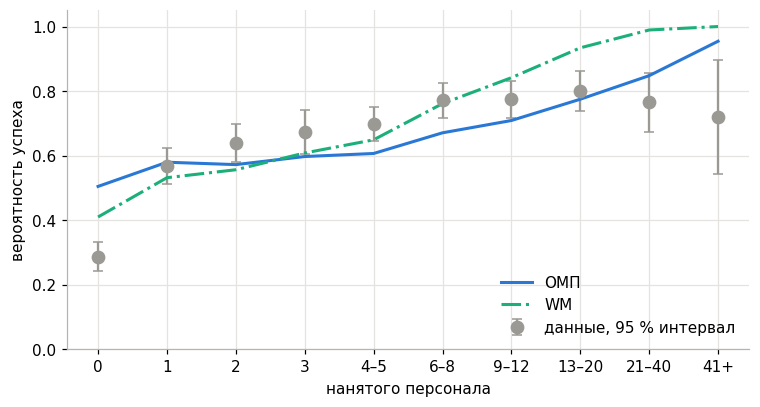

In [80]:
fig, ax = plt.subplots(figsize=(8, 4))
pos = np.arange(len(calib))
err = 1.96 * np.sqrt(calib["доля успеха"] * (1 - calib["доля успеха"]) / calib["наблюдений"])
ax.errorbar(pos, calib["доля успеха"], yerr=err, fmt="o", color=GREY, ms=8, capsize=3, label="данные, 95 % интервал")
ax.plot(pos, calib["ОМП"], color=BLUE, lw=2, label="ОМП")
ax.plot(pos, calib["WM"], color=AQUA, lw=2, ls="-.", label="WM")
ax.set(xticks=pos, xticklabels=calib.index, xlabel="нанятого персонала", ylabel="вероятность успеха", ylim=(0, 1.05))
ax.legend(loc="lower right")
plt.show()

Без персонала ОМП обещает 0.50, WM 0.41, в данных 0.29. При 4–8 людях WM тоже ближе к данным. При 13 и больше WM завышает: 0.93 против 0.80, потом 0.99 против 0.77. Доля успеха после 9–12 человек перестаёт расти, а прямая в логитах выйти на плато не может. ОМП усредняет маленькие и крупные экспедиции, WM описывает большинство: 1641 экспедиция из 2110 нанимала не больше 8 человек.

## 2.4. Сравнение функций потерь

### 2.4.1. Потеря одного наблюдения

Наблюдение с $y=1$, по горизонтали линейный предиктор $\eta=\beta'x$. Слева потеря, справа вклад в оценочное уравнение (множитель перед $x_i$). Потеря Bianco–Yohai сдвинута на константу так, чтобы при $\eta\to\infty$ обе потери стремились к нулю.

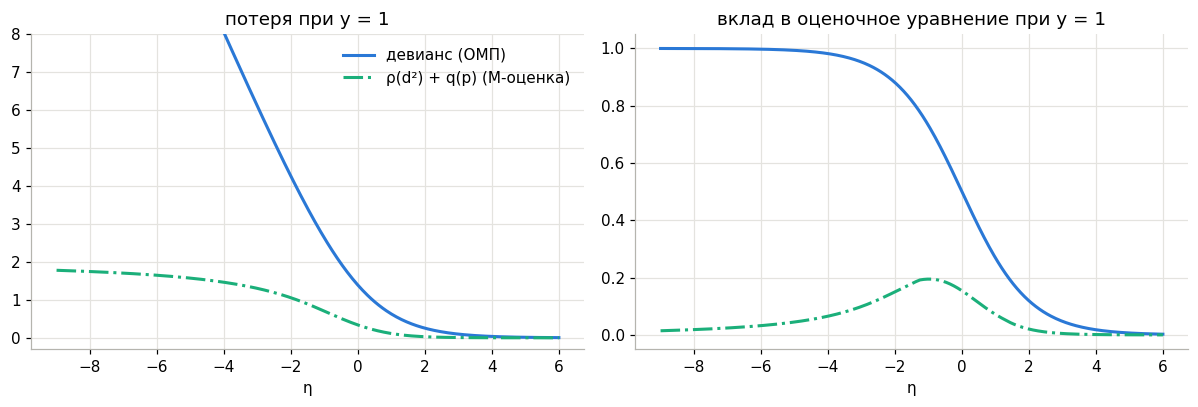

предел ρ(t) при t → ∞: 1.93


In [81]:
eta = np.linspace(-9, 6, 400)
pe = 1 / (1 + np.exp(-eta))
d2_1 = -2 * np.log(pe)
by = rho_ch(d2_1) + v_ch(pe) + v_ch(1 - pe)
by = by - by[-1]
mean = pe * (1 - pe) * (psi_ch(-2 * np.log(pe)) - psi_ch(-2 * np.log(1 - pe)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(eta, d2_1, color=BLUE, lw=2, label="девианс (ОМП)")
axes[0].plot(eta, by, color=AQUA, lw=2, ls="-.", label="ρ(d²) + q(p) (M-оценка)")
axes[0].set(xlabel="η", title="потеря при y = 1", ylim=(-0.3, 8))
axes[0].legend()
axes[1].plot(eta, 1 - pe, color=BLUE, lw=2)
axes[1].plot(eta, psi_ch(d2_1) * (1 - pe) - mean, color=AQUA, lw=2, ls="-.")
axes[1].set(xlabel="η", title="вклад в оценочное уравнение при y = 1")
plt.tight_layout()
plt.show()
print("предел ρ(t) при t → ∞:", round(float(rho_ch(np.array(1e6))), 3))

На графике множитель перед $x$. Полное влияние пропорционально ещё и $\|x\|$, при далёком $x$ его ограничивает только вес $w_i$.

### 2.4.2. Каждая оценка под каждой потерей

In [82]:
cross2 = pd.DataFrame({"девианс": [wmle_loss(b, XS, ys, one) for b in (beta_mle, beta_wmle, beta_m, beta_wm)],
                       "взвешенный девианс": [wmle_loss(b, XS, ys, w_s) for b in (beta_mle, beta_wmle, beta_m, beta_wm)],
                       "M": [wm_loss(b, XS, ys, one) for b in (beta_mle, beta_wmle, beta_m, beta_wm)],
                       "WM": [wm_loss(b, XS, ys, w_s) for b in (beta_mle, beta_wmle, beta_m, beta_wm)]},
                      index=["ОМП", "WMLE", "M", "WM"])
cross2.map("{:.4f}".format)

,девианс,взвешенный девианс,M,WM
ОМП,1.1622,1.0385,0.8938,0.7986
WMLE,1.1896,1.0263,0.8923,0.7933
M,1.1842,1.0274,0.8919,0.7938
WM,1.2657,1.0399,0.8943,0.7916


In [83]:
((cross2 / cross2.min() - 1) * 100).rename(columns=lambda c: c + ", проигрыш %").map("{:.2f}".format)

,"девианс, проигрыш %","взвешенный девианс, проигрыш %","M, проигрыш %","WM, проигрыш %"
ОМП,0.00,1.19,0.20,0.88
WMLE,2.35,0.00,0.04,0.21
M,1.89,0.11,0.00,0.27
WM,8.91,1.33,0.26,0.00


### 2.4.3. Откуда берётся потеря

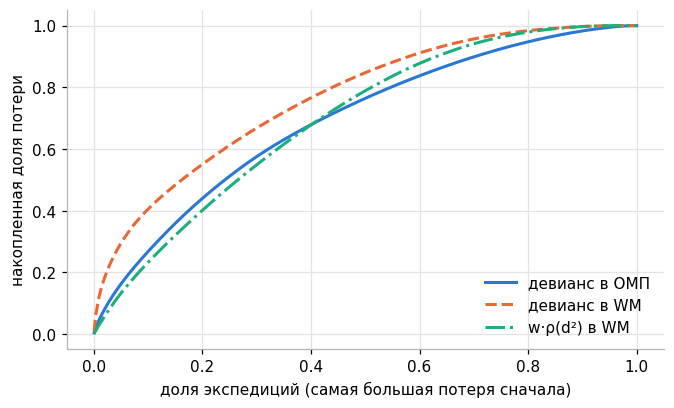

In [84]:
d2_mle, d2_wm = deviance(beta_mle, XS, ys)[1], deviance(beta_wm, XS, ys)[1]
parts2 = {"девианс в ОМП": (BLUE, "-", d2_mle), "девианс в WM": (ORANGE, "--", d2_wm),
          "w·ρ(d²) в WM": (AQUA, "-.", w_s * rho_ch(d2_wm))}
fig, ax = plt.subplots(figsize=(7, 4))
share = np.arange(1, ns + 1) / ns
for label, (color, ls, val) in parts2.items():
    ax.plot(share, np.cumsum(np.sort(val)[::-1]) / val.sum(), color=color, ls=ls, lw=2, label=label)
ax.set(xlabel="доля экспедиций (самая большая потеря сначала)", ylabel="накопленная доля потери")
ax.legend(loc="lower right")
plt.show()

In [85]:
pd.DataFrame({label: [np.sort(val)[::-1][: int(q * ns)].sum() / val.sum() for q in (0.01, 0.05, 0.10)]
              for label, (_, _, val) in parts2.items()}, index=["1 % с наибольшей потерей", "5 %", "10 %"])

,девианс в ОМП,девианс в WM,w·ρ(d²) в WM
1 % с наибольшей потерей,0.048,0.124,0.031
5 %,0.162,0.294,0.132
10 %,0.268,0.406,0.233


### 2.4.4. Профиль по коэффициенту при персонале

Как и в задании 1, фиксируем $\beta_2$ и минимизируем по остальным. Потери измерены в разных единицах, поэтому обе кривые приведены к одной шкале: 0 в минимуме, 1 при $\beta_2=0$ (персонал не учитывается).

In [86]:
def profile2(loss, grad, w, b_start, values, j=2):
    rest = [k for k in range(ps) if k != j]
    out, b0 = [], b_start[rest]
    for val in values:
        full = lambda b: np.insert(b, j, val)
        res = minimize(lambda b: loss(full(b), XS, ys, w), b0, jac=lambda b: grad(full(b), XS, ys, w)[rest], method="BFGS")
        out.append(res.fun)
    return np.array(out)

g2 = np.linspace(-0.05, 0.6, 53)
prof_mle = profile2(wmle_loss, wmle_grad, one, beta_mle, g2)
prof_wm = profile2(wm_loss, wm_grad, w_s, beta_wm, g2)
print("минимум профиля: девианс {:.3f}, WM {:.3f}".format(g2[prof_mle.argmin()], g2[prof_wm.argmin()]))

минимум профиля: девианс 0.062, WM 0.238


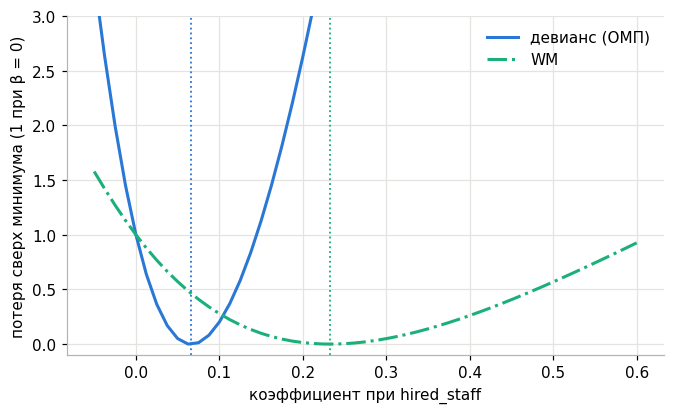

In [87]:
fig, ax = plt.subplots(figsize=(7, 4))
for v_, color, ls, label, b in [(prof_mle, BLUE, "-", "девианс (ОМП)", beta_mle), (prof_wm, AQUA, "-.", "WM", beta_wm)]:
    ax.plot(g2, (v_ - v_.min()) / (np.interp(0, g2, v_) - v_.min()), color=color, ls=ls, lw=2, label=label)
    ax.axvline(b[2], color=color, ls=":", lw=1.2)
ax.set(xlabel="коэффициент при hired_staff", ylabel="потеря сверх минимума (1 при β = 0)", ylim=(-0.1, 3))
ax.legend(loc="upper right")
plt.show()

### 2.4.5. Поверхность по двум коэффициентам

Срез по коэффициентам при `members` и `hired_staff`, остальные три зафиксированы в своей оценке (слева в ОМП, справа в WM).

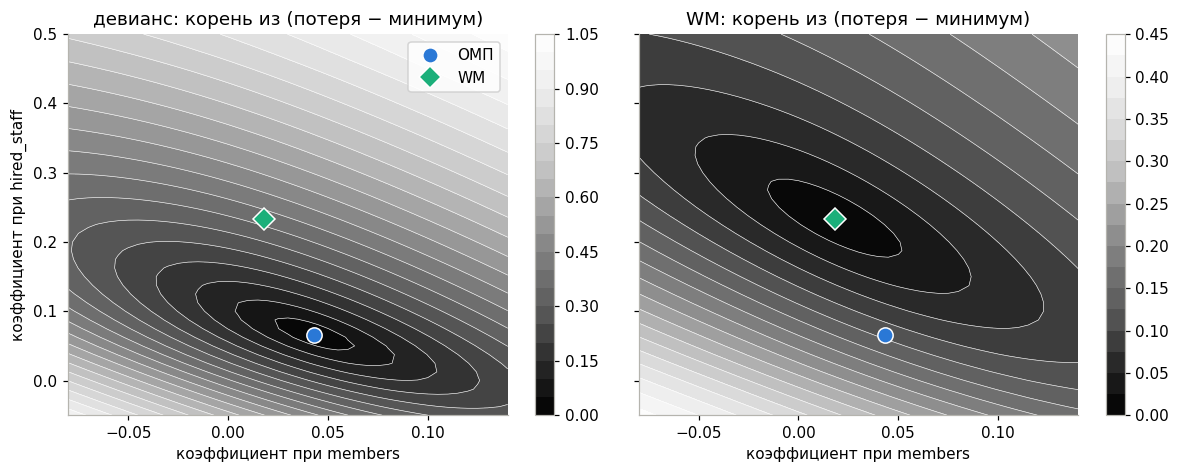

In [88]:
bm, bh = np.meshgrid(np.linspace(-0.08, 0.14, 45), np.linspace(-0.05, 0.5, 45))

def surface(loss, w, b):
    out = np.empty(bm.size)
    for i, (a, c) in enumerate(zip(bm.ravel(), bh.ravel())):
        bb = b.copy()
        bb[1], bb[2] = a, c
        out[i] = loss(bb, XS, ys, w)
    return out.reshape(bm.shape)

surf2 = {"девианс": surface(wmle_loss, one, beta_mle), "WM": surface(wm_loss, w_s, beta_wm)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (title, val) in zip(axes, surf2.items()):
    root = np.sqrt(val - val.min())
    cs = ax.contourf(bm, bh, root, 20, cmap="Greys_r")
    ax.contour(bm, bh, root, 20, colors="white", linewidths=0.4)
    ax.locator_params(axis="x", nbins=5)
    ax.plot(*beta_mle[1:3], "o", color=BLUE, ms=10, mec="white", label="ОМП")
    ax.plot(*beta_wm[1:3], "D", color=AQUA, ms=10, mec="white", label="WM")
    ax.set(title=f"{title}: корень из (потеря − минимум)", xlabel="коэффициент при members")
    ax.grid(False)
    fig.colorbar(cs, ax=ax)
axes[0].set_ylabel("коэффициент при hired_staff")
axes[0].legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

### 2.4.6. Что видно из сравнения

При уверенно ошибочном прогнозе девианс растёт линейно по $\eta$, а потеря M-оценки не превышает 1.93. Вклад наблюдения после $\eta\approx-1$ убывает, явный выброс на оценку почти не влияет.

По перекрёстной таблице ОМП проигрывает WM по потере WM 0.9 %, а WM проигрывает ОМП по девиансу 8.9 %. Сравнивать проценты между столбцами нельзя, у WM большая часть потери постоянна (слагаемое $q$).

В решении WM 1 % экспедиций даёт 12 % девианса и только 3 % взвешенной $\rho(d^2)$. WM грубо ошибается на этих экспедициях, но их вклад в оценку мал.

Минимум профиля у WM сдвинут от 0.066 к 0.233. Форма у кривых разная: девианс справа растёт круто, у WM рост умеренный.

При заданном $x$ остаток логистической регрессии принимает два значения, и форма $\rho$ целиком видна на графике одной потери как функции $\eta$, этот рисунок полезнее остальных. Контуры показывают срез, на котором остальные коэффициенты заморожены, поэтому точка чужой оценки на каждом графике условна. Профиль точнее.

## 2.5. Какие наблюдения модель считает нетипичными

In [89]:
pw = prob(XS, beta_wm)
view2 = climb[["expedition_id", "year", "season", "highpoint_date", "members", "hired_staff", "success", "termination_reason"]].assign(
    вероятность=pw, d=ds, вес_x=w_s, вес_отклика=psi_ch(d2_wm) / E)
view2[view2["success"] == 0].sort_values("вероятность", ascending=False).head(10)

,expedition_id,year,season,highpoint_date,members,hired_staff,success,termination_reason,вероятность,d,вес_x,вес_отклика
448,EVER36101,1936,Spring,1936-05-14,12,65,0,"Bad weather (storms, high winds)",1.000,33.743,0.091,0.012
463,EVER66101,1966,Spring,NaN,20,60,0,Accident (death or serious injury),1.000,26.410,0.116,0.013
407,EVER64101,1964,Spring,NaN,20,60,0,Other,1.000,26.541,0.115,0.013
401,EVER71101,1971,Spring,1971-05-20,31,55,0,"Bad weather (storms, high winds)",1.000,20.603,0.148,0.015
1730,EVER15106,2015,Spring,2015-04-25,36,43,0,Other,1.000,13.166,0.232,0.020
445,EVER33101,1933,Spring,1933-05-30,16,50,0,"Route technically too difficult, lack of exper...",1.000,25.250,0.121,0.026
461,EVER62101,1962,Spring,1962-05-30,14,44,0,"Bad weather (storms, high winds)",1.000,20.575,0.149,0.030
1521,EVER12166,2012,Spring,2012-04-29,30,30,0,"Bad conditions (deep snow, avalanching, fallin...",0.999,9.033,0.338,0.042
1747,EVER15117,2015,Spring,2015-04-25,7,28,0,Other,0.999,11.623,0.263,0.051
638,EVER01146,2001,Spring,2001-05-16,5,30,0,"Bad weather (storms, high winds)",0.999,13.963,0.219,0.051


In [90]:
fails = view2[(view2["success"] == 0) & (view2["вероятность"] > 0.85)]
print("неудач с прогнозом выше 0.85:", len(fails))
fails["year"].value_counts().head(6).to_frame("неудач").assign(
    экспедиций_в_году=lambda t: climb.groupby("year").size().reindex(t.index),
    доля_успеха_в_году=lambda t: climb.groupby("year")["success"].mean().reindex(t.index))

неудач с прогнозом выше 0.85: 83


,неудач,экспедиций_в_году,доля_успеха_в_году
year,,,
2015,24,80,0.000
2014,9,66,0.167
1992,4,33,0.485
1985,2,14,0.214
2005,2,98,0.541
2006,2,100,0.750


Когда заканчивались весенние экспедиции этих двух лет (квантили даты окончания) и, для сравнения, соседних:

In [91]:
near = climb[climb["year"].between(2013, 2016) & (climb["spring"] == 1)]
pd.to_datetime(near["termination_date"]).groupby(near["year"]).quantile([0.25, 0.5, 0.75]).dt.strftime("%d.%m").unstack()

,0.250,0.500,0.750
year,,,
2013,21.05,23.05,25.05
2014,26.04,28.04,28.05
2015,28.04,01.05,02.05
2016,22.05,24.05,26.05


Успехи с самой низкой предсказанной вероятностью:

In [92]:
view2[view2["success"] == 1].sort_values("вероятность").head(6)

,expedition_id,year,season,highpoint_date,members,hired_staff,success,termination_reason,вероятность,d,вес_x,вес_отклика
328,EVER80201,1980,Summer,1980-08-20,2,0,1,Success (main peak),0.044,3.753,0.815,0.166
24,EVER86202,1986,Summer,1986-08-30,6,0,1,Success (main peak),0.056,3.027,1.000,0.184
272,EVER84303,1984,Autumn,1984-10-20,12,0,1,Success (main peak),0.058,4.884,0.626,0.187
98,EVER91311,1991,Autumn,1991-10-07,10,0,1,Success (main peak),0.070,3.918,0.780,0.201
45,EVER87402,1987,Winter,1987-12-22,9,1,1,Success (main peak),0.075,3.380,0.905,0.209
92,EVER83306,1983,Autumn,1983-10-08,5,2,1,Success (main peak),0.078,3.117,0.981,0.212


Разница между ОМП и WM может идти от формы зависимости. Заменим `members` и `hired_staff` на логарифмы.

In [93]:
Xl = XS.copy()
Xl[:, 1:3] = np.log1p(XS[:, 1:3])
log_mle = minimize(wmle_loss, np.zeros(ps), args=(Xl, ys, one), jac=wmle_grad, method="BFGS").x
log_wm = minimize(wm_loss, log_mle, args=(Xl, ys, w_s), jac=wm_grad, method="BFGS").x
pd.DataFrame([log_mle, log_wm], columns=["const", "ln(1+members)", "ln(1+hired_staff)", "decade", "spring"],
             index=["ОМП", "WM"]).assign(**{"ln L": [-ns / 2 * wmle_loss(b, Xl, ys, one) for b in (log_mle, log_wm)]})

,const,ln(1+members),ln(1+hired_staff),decade,spring,ln L
ОМП,-2.530,0.198,0.800,0.382,1.667,-1161.437
WM,-2.922,0.137,1.022,0.302,2.024,-1170.001


In [94]:
print("WM / ОМП для персонала: в исходной шкале {:.2f}, в логарифмах {:.2f}".format(beta_wm[2] / beta_mle[2], log_wm[2] / log_mle[2]))
print("ln L для ОМП: исходная шкала {:.1f}, логарифмы {:.1f}".format(-ns / 2 * wmle_loss(beta_mle, XS, ys, one), -ns / 2 * wmle_loss(log_mle, Xl, ys, one)))

WM / ОМП для персонала: в исходной шкале 3.51, в логарифмах 1.28
ln L для ОМП: исходная шкала -1226.1, логарифмы -1161.4


Неудач с прогнозом успеха больше 0.85 набралось 83. Из них 24 приходятся на 2015 год, когда не поднялась ни одна из 80 экспедиций: 25 апреля было землетрясение. Ещё 9 на 2014 год, доля успеха 17 %, 18 апреля сошла лавина в ледопаде Кхумбу. Даты это подтверждают: в 2014 году половина весенних экспедиций закончилась к 28 апреля, в 2015 три четверти ко 2 мая, тогда как в 2013 и 2016 медиана 23–24 мая. Причина неудачи с размером экспедиции не связана, это выбросы в ответе.

Шесть из десяти самых уверенных ошибок приходятся на экспедиции 1933–1971 годов с 44–65 нанятыми: далёкие $x$ и неудача. Вес по $x$ у них 0.09–0.15, вес отклика 0.01–0.03.

Самый нетипичный успех случился летом 1980 года, 2 участника без персонала, 20 августа. Это соло-восхождение Месснера.

В логарифмах ОМП и WM расходятся в 1.28 раза вместо 3.51, а $\ln L$ вырос с −1226.1 до −1161.4 при том же числе параметров. Значит, расхождение в основном создаёт форма зависимости: в логарифмах крупные экспедиции перестают быть далёкими точками.

---
# Выводы

По экспедициям на Эверест МНК получает отрицательный тренд персонала по годам, MM и GM положительный. На 1 % экспедиций у МНК приходится 40 % квадратичной потери, в основном это ранние и крупные экспедиции с большими остатками и leverage. MM и GM близки, MM устойчивее (точка срыва 0.5), GM проще.

Выбросы в линейной модели во многом созданы гетероскедастичностью: с функцией $h$ их 96 вместо 211, а SE меньше в 1.8–2.9 раза. Выбросами по обеим моделям остались 46 экспедиций, у них по медиане 26 нанятых на 9–10 участников.

В логистической модели взвешенная M-оценка подняла коэффициент при персонале с 0.066 до 0.233: далёкие неудачи, в том числе 2014 и 2015 годов, прижимали его к нулю. Но в логарифмах разница почти исчезла, то есть большую её часть создаёт нелинейность.

Квадратичная потеря и девианс не ограничены, бисквадрат и потеря Bianco–Yohai ограничены. Сравнивать их по профилям удобнее, чем по срезам, а полную поверхность можно нарисовать только для двух параметров.